# 01 - Data Quality & Validation

### Purpose
Before analysing SOXL's downside risk, we need to verify that our historical market data is accurate, complete, and consistent.

This notebook documents the data validation process for four datasets:

- **SOXL:** Direxion Daily Semiconductor Bull 3X Shares
- **SOXS:** Direxion Daily Semiconductor Bear 3X Shares
- **SOXX:** iShares Semiconductor ETF
- **NASDAQSOX:** PHLX Semiconductor Sector Index, retrieved from FRED

### Validation Checklist
1. Data completeness and missing values
2. Trading-date alignment
3. Stock splits and dividend adjustments
4. Extreme daily returns
5. Corporate action verification
6. Final data-quality decisions

**Historical period:** March 2010 – October 30, 2026

**Data sources:** Yahoo Finance and Federal Reserve Economic Data (FRED)

**Status:** Validation in progress


In [1]:
from pathlib import Path
import pandas as pd

# Jupyter is running from the project's root directory.
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Load the original historical datasets.
soxl = pd.read_csv(DATA_DIR / "soxl_yahoo_daily.csv")
soxs = pd.read_csv(DATA_DIR / "soxs_yahoo_daily.csv")
soxx = pd.read_csv(DATA_DIR / "soxx_yahoo_daily.csv")
fred = pd.read_csv(DATA_DIR / "nasdaqsox_fred_original.csv")

# Display the number of observations in each dataset.
summary = pd.DataFrame({
    "Dataset": ["SOXL", "SOXS", "SOXX", "NASDAQSOX"],
    "Observations": [len(soxl), len(soxs), len(soxx), len(fred)]
})

display(summary)

,Dataset,Observations
0,SOXL,4187
1,SOXS,4187
2,SOXX,4195
3,NASDAQSOX,4350


## 1. Initial Data Quality Assessment

### Objective
Check all four datasets for missing values, duplicate dates,
invalid dates, and nonpositive prices.

### Why this matters
Errors in historical prices can distort return calculations,
volatility estimates, and downside risk measurements.

We will preserve the original downloaded data and investigate
any issues before making cleaning decisions.

In [2]:
# Organize our four datasets into a dictionary.
datasets = {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx,
    "NASDAQSOX": fred
}

results = []

for name, df in datasets.items():

    # FRED uses a different date column name.
    date_col = "observation_date" if name == "NASDAQSOX" else "Date"

    dates = pd.to_datetime(df[date_col], errors="coerce")

    results.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Missing Values": df.isna().sum().sum(),
        "Duplicate Dates": dates.duplicated().sum(),
        "Invalid Dates": dates.isna().sum()
    })

quality_summary = pd.DataFrame(results)

display(quality_summary)

,Dataset,Total Rows,Missing Values,Duplicate Dates,Invalid Dates
0,SOXL,4187,0,0,0
1,SOXS,4187,0,0,0
2,SOXX,4195,0,0,0
3,NASDAQSOX,4350,155,0,0


### 1.1 Investigating Missing FRED Observations

The initial assessment identified 155 missing NASDAQSOX values.

These may represent non-trading days, such as stock market holidays, rather than errors in the dataset.

To investigate, we compare the dates with valid FRED observations against SOXX's trading dates.

**Validation criteria:** If both datasets contain the same trading dates, we can exclude the missing FRED observations during data cleaning without inventing replacement prices.

In [3]:
# Convert both date columns into datetime format.
fred_dates = pd.to_datetime(fred["observation_date"])
soxx_dates = pd.to_datetime(soxx["Date"])

# Keep only FRED dates with an actual index value.
fred_valid_dates = set(
    fred_dates[fred["NASDAQSOX"].notna()]
)

# Collect SOXX trading dates.
soxx_trading_dates = set(soxx_dates)

# Compare the two trading calendars.
calendar_results = pd.DataFrame({
    "Check": [
        "FRED missing observations",
        "FRED valid trading dates",
        "SOXX trading dates",
        "FRED dates absent from SOXX",
        "SOXX dates absent from FRED"
    ],
    "Result": [
        fred["NASDAQSOX"].isna().sum(),
        len(fred_valid_dates),
        len(soxx_trading_dates),
        len(fred_valid_dates - soxx_trading_dates),
        len(soxx_trading_dates - fred_valid_dates)
    ]
})

display(calendar_results)

# Display examples of dates with missing FRED values.
missing_fred = fred[fred["NASDAQSOX"].isna()]

display(missing_fred.head(10))

,Check,Result
0,FRED missing observations,155
1,FRED valid trading dates,4195
2,SOXX trading dates,4195
3,FRED dates absent from SOXX,0
4,SOXX dates absent from FRED,0


,observation_date,NASDAQSOX
24,2010-04-02,NaN
65,2010-05-31,NaN
90,2010-07-05,NaN
135,2010-09-06,NaN
193,2010-11-25,NaN
214,2010-12-24,NaN
230,2011-01-17,NaN
255,2011-02-21,NaN
299,2011-04-22,NaN
325,2011-05-30,NaN


### Findings and Cleaning Decision

The FRED dataset contains 155 missing index values. Investigation shows that all 4,195 valid FRED observation dates match SOXX's trading calendar exactly.

**Conclusion:** The missing observations occur outside the trading calendar represented by SOXX. They do not indicate missing index prices on those trading days.

**Cleaning decision:**
- Preserve the original FRED dataset unchanged.
- Exclude rows with missing index values when preparing the cleaned dataset.
- Never replace missing prices with zero.

This ensures that our calculations use actual market observations without introducing artificial returns.

## 2. ETF Trading-Date Alignment

### Objective
Verify that SOXL, SOXS and SOXX contain observations for the same trading days.

### Why this matters
Comparing returns from different dates would produce misleading results.

We will identify the common trading period and determine whether any ETFs have additional observations outside that period.

In [4]:
# Convert ETF date columns into sets for comparison.
etf_dates = {}

for ticker, df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():
    etf_dates[ticker] = set(pd.to_datetime(df["Date"]))

# Find dates shared by all three ETFs.
common_dates = set.intersection(*etf_dates.values())

# Create a summary table.
alignment_summary = pd.DataFrame({
    "ETF": ["SOXL", "SOXS", "SOXX"],
    "Total Trading Days": [
        len(etf_dates["SOXL"]),
        len(etf_dates["SOXS"]),
        len(etf_dates["SOXX"])
    ],
    "Shared Trading Days": [len(common_dates)] * 3,
    "Additional Dates": [
        len(etf_dates[ticker] - common_dates)
        for ticker in ["SOXL", "SOXS", "SOXX"]
    ]
})

display(alignment_summary)

print("First shared date:", min(common_dates).date())
print("Last shared date:", max(common_dates).date())
print("SOXL and SOXS calendars match:",
      etf_dates["SOXL"] == etf_dates["SOXS"])

,ETF,Total Trading Days,Shared Trading Days,Additional Dates
0,SOXL,4187,4187,0
1,SOXS,4187,4187,0
2,SOXX,4195,4187,8


First shared date: 2010-03-11
Last shared date: 2026-10-30
SOXL and SOXS calendars match: True


### Findings and Methodology Decision

All three ETFs share 4,187 trading dates between March 11, 2010 and October 30, 2026.

SOXL and SOXS have identical trading calendars. SOXX contains eight additional observations before the other two ETFs begin.

**Decision:** Use the 4,187 common dates when comparing all three ETFs. The datasets will be joined by trading date rather than row position.

This preserves the original datasets while ensuring that daily observations are comparable.

## 3. Stock Split Validation

### Objective
Identify historical stock splits and verify that they do not create artificial investment gains or losses in our calculations.

### Why this matters
A stock split changes the number of shares and price per share without directly changing the total value of an investment.

For example, a 4-for-1 forward split converts one $100 share into four $25 shares.

A reverse split has the opposite effect.

If historical prices are not adjusted for these changes, calculated returns and volatility may be misleading.

We will first identify the recorded split events for SOXL, SOXS and SOXX.

In [5]:
from fractions import Fraction

split_results = []

for ticker, df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    # Select dates when a stock split occurred.
    splits = df[df["Stock Splits"] > 0]

    for _, event in splits.iterrows():

        ratio = event["Stock Splits"]

        # Convert the numerical ratio into a readable form.
        fraction = Fraction(float(ratio)).limit_denominator(100)

        split_results.append({
            "ETF": ticker,
            "Date": event["Date"],
            "Split Ratio": f"{fraction.numerator}-for-{fraction.denominator}",
            "Type": "Forward" if ratio > 1 else "Reverse"
        })

split_summary = pd.DataFrame(split_results)

display(split_summary)

print("\nTotal split events:", len(split_summary))

,ETF,Date,Split Ratio,Type
0,SOXL,2015-05-20,4-for-1,Forward
1,SOXL,2021-03-02,15-for-1,Forward
2,SOXS,2011-02-24,1-for-5,Reverse
3,SOXS,2013-08-20,1-for-4,Reverse
4,SOXS,2015-05-20,1-for-4,Reverse
5,SOXS,2017-05-01,1-for-5,Reverse
6,SOXS,2019-06-28,1-for-10,Reverse
7,SOXS,2020-08-28,1-for-12,Reverse
8,SOXS,2022-03-28,1-for-10,Reverse
9,SOXS,2024-04-15,1-for-10,Reverse



Total split events: 13


### 3.1 Verifying Split-Adjusted Returns

The previous assessment identified 13 stock split events across the three ETFs.

We now calculate daily returns around each split date using both `Close` and `Adj Close`.

The daily return formula is:

$$
R_t = \frac{P_t-P_{t-1}}{P_{t-1}}\times100
$$

Where:
- $R_t$ = daily return in percentage terms
- $P_t$ = closing price on the current trading day
- $P_{t-1}$ = closing price on the previous trading day

**Validation objective:** Check for artificial price changes caused by stock splits. A correctly split-adjusted price history should not show a large discontinuity solely because the number of shares changed.

In [6]:
split_return_results = []

for ticker, df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    # Work with a dated, sorted copy of each dataset.
    df = df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    # Calculate daily percentage returns.
    df["Close Return (%)"] = (
        df["Close"].pct_change(fill_method=None) * 100
    )

    df["Adjusted Return (%)"] = (
        df["Adj Close"].pct_change(fill_method=None) * 100
    )

    # Keep only observations with recorded stock splits.
    split_days = df[df["Stock Splits"] > 0]

    for _, event in split_days.iterrows():
        split_return_results.append({
            "ETF": ticker,
            "Date": event["Date"].strftime("%Y-%m-%d"),
            "Split Ratio": event["Stock Splits"],
            "Close Return (%)": event["Close Return (%)"],
            "Adjusted Return (%)": event["Adjusted Return (%)"]
        })

split_returns = pd.DataFrame(split_return_results)

display(split_returns.round(2))

,ETF,Date,Split Ratio,Close Return (%),Adjusted Return (%)
0,SOXL,2015-05-20,4.00,0.52,0.52
1,SOXL,2021-03-02,15.00,-9.42,-9.42
2,SOXS,2011-02-24,0.20,-4.97,-4.97
3,SOXS,2013-08-20,0.25,-1.91,-1.91
4,SOXS,2015-05-20,0.25,-0.47,-0.47
5,SOXS,2017-05-01,0.20,-2.99,-2.99
6,SOXS,2019-06-28,0.10,0.21,0.21
7,SOXS,2020-08-28,0.08,-5.92,-5.92
8,SOXS,2022-03-28,0.10,-1.81,-1.81
9,SOXS,2024-04-15,0.10,4.03,4.03


### 3.2 Findings and Methodology Decision

The dataset contains 13 recorded stock split events:

- SOXL: 2 forward splits
- SOXS: 10 reverse splits
- SOXX: 1 forward split

Comparing daily returns on all recorded split dates revealed no artificial split-sized price discontinuities.

For example, SOXL's 15-for-1 split on March 2, 2021, produced a -9.42% daily return rather than an artificial loss exceeding 90%.

**Conclusion:** The downloaded price histories appear to account for stock splits correctly. This is an initial consistency check, not independent verification of every corporate action.

**Methodology decision:** Do not apply stock split adjustments a second time. Preserve the original datasets and investigate dividend adjustments separately.

## 4. Dividend Adjustment Validation

### Objective
Compare closing prices and dividend-adjusted prices to determine which series is appropriate for calculating investment returns and downside risk.

### Why this matters
ETFs may distribute income to shareholders. These distributions can affect the fund's share price without representing an equivalent loss in total investment value.

Two price columns are available:

- **Close:** Historical closing prices adjusted for stock splits.
- **Adj Close:** Closing prices adjusted for stock splits and historical distributions.

Using dividend-adjusted prices can provide a better measure of historical investor returns.

We will identify dividend events and compare price-only and adjusted returns before making our final methodology decision.

In [7]:
dividend_results = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()

    # Ensure dates are ordered correctly.
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    # Count dividend distribution events.
    dividend_events = (df["Dividends"] > 0).sum()

    # Compare Close and Adj Close price levels.
    different_prices = (
        (df["Close"] - df["Adj Close"]).abs() > 1e-6
    ).sum()

    # Calculate price-only and adjusted daily returns.
    df["Close Return (%)"] = (
        df["Close"].pct_change(fill_method=None) * 100
    )

    df["Adjusted Return (%)"] = (
        df["Adj Close"].pct_change(fill_method=None) * 100
    )

    dividend_results.append({
        "ETF": ticker,
        "Dividend Events": dividend_events,
        "Days with Different Price Levels": different_prices,
        "Largest Recorded Dividend": df["Dividends"].max()
    })

dividend_summary = pd.DataFrame(dividend_results)

display(dividend_summary)

,ETF,Dividend Events,Days with Different Price Levels,Largest Recorded Dividend
0,SOXL,32,4158,1.842670e-01
1,SOXS,26,4158,6.844800e+08
2,SOXX,65,4161,2.002220e-01


### 4.1 Investigating Unusually Large SOXS Distributions

The dividend summary identified an unusually large recorded SOXS distribution of 684,480,000.

SOXS has experienced ten reverse splits during the historical period. These may explain why historical distribution values appear unusually large on a split-adjusted basis.

We will examine the largest recorded distributions relative to the previous trading day's closing price.

**Status:** Under investigation. No historical observations will be changed until the adjustment method is verified.

In [8]:
# Create a copy so the original data stays unchanged.
soxs_check = soxs.copy()

# Sort observations in chronological order.
soxs_check["Date"] = pd.to_datetime(soxs_check["Date"])
soxs_check = soxs_check.sort_values("Date").reset_index(drop=True)

# Find the closing price immediately before each date.
soxs_check["Previous Close"] = soxs_check["Close"].shift(1)

# Compare distributions with the previous closing price.
soxs_check["Dividend Yield (%)"] = (
    soxs_check["Dividends"] /
    soxs_check["Previous Close"] * 100
)

# Show the ten largest recorded distributions.
largest_dividends = (
    soxs_check[soxs_check["Dividends"] > 0]
    .nlargest(10, "Dividends")
    [["Date", "Dividends", "Previous Close", "Dividend Yield (%)"]]
)

display(
    largest_dividends.style.format({
        "Dividends": "{:,.2f}",
        "Previous Close": "{:,.2f}",
        "Dividend Yield (%)": "{:.4f}%"
    })
)

,Date,Dividends,Previous Close,Dividend Yield (%)
193,2010-12-14 00:00:00,"684,480,000.00","15,580,800,000.00",4.3931%
260,2011-03-22 00:00:00,"143,040,000.00","12,278,400,000.00",1.1650%
2215,2018-12-27 00:00:00,"141,600.00","33,768,000.00",0.4193%
2401,2019-09-24 00:00:00,"61,200.00","8,829,600.00",0.6931%
2151,2018-09-25 00:00:00,"48,000.00","22,416,000.00",0.2141%
2270,2019-03-19 00:00:00,"40,800.00","16,368,000.00",0.2493%
2020,2018-03-20 00:00:00,"31,200.00","25,968,000.00",0.1201%
2083,2018-06-19 00:00:00,"19,200.00","22,704,000.00",0.0846%
2464,2019-12-23 00:00:00,"15,360.00","5,035,200.00",0.3051%
2526,2020-03-24 00:00:00,"12,720.00","7,008,000.00",0.1815%


### 4.2 Reconstructing Historical SOXS Distributions

The largest recorded SOXS dividends are accompanied by proportionally large historical closing prices.

To investigate whether subsequent reverse splits explain these values, we calculate the cumulative split factor after each historical distribution.

We then divide the recorded dividend and historical price by that factor to estimate their values on the original share basis.

This is an internal consistency test. Independent source verification remains necessary.

In [9]:
from fractions import Fraction

# Select three historical distributions for investigation.
dates_to_check = pd.to_datetime([
    "2010-12-14",
    "2011-03-22",
    "2020-03-24"
])

comparison_results = []

for target in dates_to_check:

    event = soxs_check.loc[
        soxs_check["Date"] == target
    ].iloc[0]

    # Find every stock split occurring AFTER this dividend.
    later_splits = soxs_check.loc[
        (soxs_check["Date"] > target) &
        (soxs_check["Stock Splits"] > 0),
        "Stock Splits"
    ]

    # Calculate the cumulative price adjustment factor.
    # Fractions avoid rounding issues with ratios like 1-for-12.
    factor = Fraction(1, 1)

    for ratio in later_splits:
        factor /= Fraction(float(ratio)).limit_denominator(1000)

    factor = float(factor)

    comparison_results.append({
        "Date": target.strftime("%Y-%m-%d"),
        "Later Split Factor": factor,
        "Implied Original Dividend": event["Dividends"] / factor,
        "Implied Original Previous Close": event["Previous Close"] / factor
    })

split_adjustment_check = pd.DataFrame(comparison_results)

display(
    split_adjustment_check.style.format({
        "Later Split Factor": "{:,.0f}",
        "Implied Original Dividend": "${:.4f}",
        "Implied Original Previous Close": "${:,.2f}"
    })
)

,Date,Later Split Factor,Implied Original Dividend,Implied Original Previous Close
0,2010-12-14,"960,000,000",$0.7130,$16.23
1,2011-03-22,"192,000,000",$0.7450,$63.95
2,2020-03-24,"240,000",$0.0530,$29.20



### 4.3 Findings — Historical Dividend Scaling

The unusually large SOXS distributions appear to result from cumulative reverse-split adjustments. Historical dividend amounts and closing prices have both been scaled to reflect subsequent changes in the number of shares.

#### Reconstructed Historical Distributions

| Distribution Date | Later Reverse-Split Factor | Reconstructed Dividend (USD) |
|---|---:|---:|
| 2010-12-14 | 960,000,000 | 0.7130 |
| 2011-03-22 | 192,000,000 | 0.7450 |
| 2020-03-24 | 240,000 | 0.0530 |

#### Interpretation

Dividing the reported distributions by their cumulative subsequent reverse-split factors produces much smaller amounts on the historical share basis.

For example, the December 2010 distribution falls from 684.48 million USD on the current split-adjusted basis to approximately 0.7130 USD per historical share.

The reconstructed amounts are consistent with the explanation that subsequent reverse splits account for the unusually large figures.

#### Validation Outcome

**Finding:** The apparent dividend anomalies are consistent with historical reverse-split adjustments rather than literal payments of millions of dollars per share.

**Limitation:** These calculations establish internal consistency. Full independent verification of the distributions remains outstanding.

**Next step:** Compare dividend-inclusive daily returns against returns calculated from `Adj Close` to confirm whether the price adjustments are suitable for risk modelling.



### 4.4 Validating Dividend-Adjusted Returns

**Objective:** Determine whether returns calculated from `Adj Close` are consistent with returns that explicitly account for dividend distributions.

We compare two approaches:

1. **Dividend-inclusive return:** The daily price change plus the recorded cash distribution, divided by the previous closing price.
2. **Adjusted return:** The daily percentage change calculated from `Adj Close`.

Both methods should produce similar returns when the price and dividend data use a consistent share-adjustment basis.

We will examine the differences across all recorded dividend dates and investigate any material discrepancies before selecting the final return series.


In [10]:

dividend_checks = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    # Get the previous day's closing prices.
    df["Previous Close"] = df["Close"].shift(1)
    df["Previous Adj Close"] = df["Adj Close"].shift(1)

    # Calculate dividend-inclusive returns.
    df["Dividend-Inclusive Return (%)"] = (
        (df["Close"] + df["Dividends"])
        / df["Previous Close"] - 1
    ) * 100

    # Calculate returns using adjusted closing prices.
    df["Adjusted Return (%)"] = (
        df["Adj Close"] / df["Previous Adj Close"] - 1
    ) * 100

    # Calculate the difference in percentage points.
    df["Difference (pp)"] = (
        df["Dividend-Inclusive Return (%)"]
        - df["Adjusted Return (%)"]
    )

    # Only examine dates when dividends were recorded.
    events = df.loc[
        df["Dividends"] > 0,
        ["Date", "Dividends",
         "Dividend-Inclusive Return (%)",
         "Adjusted Return (%)",
         "Difference (pp)"]
    ].copy()

    events.insert(0, "ETF", ticker)
    dividend_checks.append(events)

# Combine all three ETFs into one results table.
dividend_return_checks = pd.concat(
    dividend_checks, ignore_index=True
)

# Summarize discrepancies for each ETF.
dividend_validation_summary = (
    dividend_return_checks.groupby("ETF")
    .agg(
        Events=("Date", "count"),
        Mean_Absolute_Difference_pp=(
            "Difference (pp)",
            lambda x: x.abs().mean()
        ),
        Maximum_Absolute_Difference_pp=(
            "Difference (pp)",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
)

display(dividend_validation_summary.round(5))

# Show the ten largest discrepancies for investigation.
largest_differences = (
    dividend_return_checks
    .sort_values(
        "Difference (pp)",
        key=lambda x: x.abs(),
        ascending=False
    )
    .head(10)
    .copy()
)

largest_differences["Date"] = (
    largest_differences["Date"].dt.strftime("%Y-%m-%d")
)

print("Ten largest dividend-return discrepancies:")
display(largest_differences.round(4))


,ETF,Events,Mean_Absolute_Difference_pp,Maximum_Absolute_Difference_pp
0,SOXL,32,0.01177,0.12778
1,SOXS,26,0.04619,0.27464
2,SOXX,65,0.00313,0.01234


Ten largest dividend-return discrepancies:


,ETF,Date,Dividends,Dividend-Inclusive Return (%),Adjusted Return (%),Difference (pp)
56,SOXS,2026-06-23,3.800000e-01,23.5758,23.8504,-0.2746
2,SOXL,2016-12-20,1.843000e-01,2.6768,2.8046,-0.1278
50,SOXS,2024-12-23,6.040000e+01,-8.9485,-9.0670,0.1185
32,SOXS,2010-12-14,6.844800e+08,1.9285,2.0171,-0.0886
57,SOXS,2026-09-22,4.360000e-01,-7.0026,-7.0901,0.0875
44,SOXS,2023-06-21,2.380000e+02,7.3618,7.4477,-0.0859
46,SOXS,2023-12-21,1.400000e+02,-7.8431,-7.9268,0.0837
52,SOXS,2025-06-24,1.120000e+01,-11.2487,-11.3163,0.0676
41,SOXS,2020-03-24,1.272000e+04,-33.0034,-33.0634,0.0600
48,SOXS,2024-06-25,5.500000e+01,-4.6420,-4.6957,0.0538



### 4.5 Verifying Yahoo Finance's Dividend Adjustment Method

The two return calculations produced small but measurable differences.

This does not necessarily indicate incorrect data. Yahoo Finance adjusts historical prices using dividend multipliers based on the previous closing price.

**Objective:** Reconstruct Yahoo's expected adjusted return using the reported closing prices and dividends.

We will compare:

- The adjusted return calculated from `Adj Close`.
- The return reconstructed using Yahoo's documented dividend multiplier.

Only dividend dates without stock splits are included in this test.

**Reference:** Yahoo Finance Help — "What is the adjusted close?"
https://in.help.yahoo.com/kb/adjusted-close-sln28256.html


In [11]:

yahoo_results = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    previous_close = df["Close"].shift(1)
    previous_adjusted = df["Adj Close"].shift(1)

    # Return calculated from Yahoo's adjusted prices.
    actual = (
        df["Adj Close"] / previous_adjusted - 1
    ) * 100

    # Return implied by Yahoo's dividend multiplier.
    expected = (
        df["Close"] /
        (previous_close - df["Dividends"]) - 1
    ) * 100

    # Only include dividend dates without a stock split.
    valid = (
        (df["Dividends"] > 0) &
        (df["Stock Splits"] == 0) &
        (previous_close > df["Dividends"])
    )

    for i in df.index[valid]:
        yahoo_results.append({
            "ETF": ticker,
            "Date": df.loc[i, "Date"],
            "Yahoo Formula Return (%)": expected.loc[i],
            "Adj Close Return (%)": actual.loc[i],
            "Difference (pp)": expected.loc[i] - actual.loc[i]
        })

yahoo_check = pd.DataFrame(yahoo_results)

# Summarize the differences across dividend events.
yahoo_summary = (
    yahoo_check.groupby("ETF")
    .agg(
        Events=("Date", "count"),
        Mean_Absolute_Difference_pp=(
            "Difference (pp)", lambda x: x.abs().mean()
        ),
        Maximum_Absolute_Difference_pp=(
            "Difference (pp)", lambda x: x.abs().max()
        )
    )
    .reset_index()
)

display(yahoo_summary.round(6))

# Inspect the five largest remaining differences.
largest_yahoo_differences = (
    yahoo_check.loc[
        yahoo_check["Difference (pp)"].abs().nlargest(5).index
    ]
    .copy()
)

largest_yahoo_differences["Date"] = (
    largest_yahoo_differences["Date"].dt.strftime("%Y-%m-%d")
)

display(largest_yahoo_differences.round(6))


,ETF,Events,Mean_Absolute_Difference_pp,Maximum_Absolute_Difference_pp
0,SOXL,32,0.000009,0.000030
1,SOXS,26,0.000010,0.000026
2,SOXX,65,0.000016,0.000067


,ETF,Date,Yahoo Formula Return (%),Adj Close Return (%),Difference (pp)
85,SOXX,2017-09-26,-0.157919,-0.157986,0.000067
69,SOXX,2013-09-24,0.631465,0.631519,-0.000054
77,SOXX,2015-09-25,0.549688,0.549642,0.000047
88,SOXX,2018-06-26,0.355141,0.355183,-0.000042
65,SOXX,2012-09-25,-2.489368,-2.489327,-0.000041



### 4.6 Final Findings — Dividend Adjustment Validation

#### Summary of Results

The dividend-adjustment assessment identified 32 SOXL, 26 SOXS, and 65 SOXX distribution events.

Initial comparisons between cash-dividend-inclusive returns and `Adj Close` returns revealed small differences. These differences were substantially reduced when Yahoo Finance's historical dividend-adjustment formula was reconstructed.

| ETF | Maximum Difference from Yahoo Formula (pp) |
|---|---:|
| SOXL | 0.000030 |
| SOXS | 0.000026 |
| SOXX | 0.000067 |

#### Interpretation

The extremely small residual differences support the internal consistency of the adjusted-price calculations.

Earlier investigations also showed that unusually large historical SOXS distributions are consistent with cumulative reverse-split adjustments.

#### Methodology Decision

**Primary return series:** Use `Adj Close` to calculate historical ETF returns and downside-risk measures, subject to remaining source validation.

**Supporting data:** Retain `Close`, `Dividends`, and `Stock Splits` for additional checks and documentation.

Dividends will not be added again to returns calculated from `Adj Close`, since this would risk double-counting distributions.

#### Remaining Limitations

- Independent verification of all historical corporate actions is incomplete.
- The accuracy of historical market prices still requires further checks.
- Benchmark consistency must be assessed separately.

**Status:** Dividend-adjustment consistency checks completed. Independent source verification remains outstanding.



## 5. Price Integrity Checks

### Objective

Verify that the downloaded datasets do not contain zero, negative, or invalid price observations.

### Why This Matters

Invalid market prices can distort percentage returns, volatility estimates, and downside-risk calculations.

A zero or negative ETF price is not a valid daily market price. Missing index observations are assessed separately because they may represent non-trading days.

We will examine all available ETF price columns and the FRED semiconductor index.


In [12]:

price_check_results = []

for name, df in datasets.items():

    if name == "NASDAQSOX":
        price_columns = ["NASDAQSOX"]
    else:
        price_columns = [
            "Open", "High", "Low", "Close", "Adj Close"
        ]

    for column in price_columns:

        prices = pd.to_numeric(df[column], errors="coerce")

        price_check_results.append({
            "Dataset": name,
            "Price Column": column,
            "Missing / Invalid Values": prices.isna().sum(),
            "Zero Prices": (prices == 0).sum(),
            "Negative Prices": (prices < 0).sum()
        })

price_integrity = pd.DataFrame(price_check_results)

display(price_integrity)


,Dataset,Price Column,Missing / Invalid Values,Zero Prices,Negative Prices
0,SOXL,Open,0,0,0
1,SOXL,High,0,0,0
2,SOXL,Low,0,0,0
3,SOXL,Close,0,0,0
4,SOXL,Adj Close,0,0,0
5,SOXS,Open,0,0,0
6,SOXS,High,0,0,0
7,SOXS,Low,0,0,0
8,SOXS,Close,0,0,0
9,SOXS,Adj Close,0,0,0



### 5.1 Findings — Price Integrity

The price integrity assessment examined 16 price columns across the four historical datasets.

**Results:**
- SOXL, SOXS, and SOXX contain no missing, zero, or negative values in their five price columns.
- NASDAQSOX contains 155 missing index observations, previously confirmed to fall outside SOXX's trading calendar.
- No zero or negative observed prices were identified.

#### Validation Outcome

**Finding:** All observed prices passed the nonpositive-price screening.

**Decision:** Preserve the original datasets. Exclude FRED's missing index observations when preparing aligned trading-day data.

**Limitation:** This test does not establish that every positive price is accurate. Unusually large market movements and historical corporate actions still require investigation.

**Status:** Initial price integrity validation completed.



## 6. Extreme Daily Return Validation

### Objective

Identify unusually large daily returns in SOXL, SOXS, and SOXX and determine whether they represent genuine market movements or potential data errors.

### Method

Daily returns are calculated using `Adj Close`, which passed the internal dividend-adjustment consistency tests.

For each ETF, we will:

1. Identify the eight largest absolute daily returns.
2. Count trading days with returns greater than +30% or less than -30%.
3. Compare unusually large movements across the three ETFs.
4. Investigate suspicious dates using historical market evidence.

### Why This Matters

Leveraged ETFs can experience substantial daily price movements. Removing extreme observations without investigation could underestimate downside risk.

The 30% threshold is used only to flag observations for review, not to define errors.

Diagnostic visualizations will be used where they help assess whether large movements are consistent across the ETFs.


In [13]:

# Section 6.1 — Screen for extreme daily returns

extreme_results = []
extreme_summary = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date").reset_index(drop=True)

    # Calculate daily adjusted percentage returns.
    df["Adjusted Return (%)"] = (
        df["Adj Close"].pct_change(fill_method=None) * 100
    )

    # Calculate the absolute magnitude of each return.
    df["Absolute Return (%)"] = df["Adjusted Return (%)"].abs()

    # Find the eight largest daily movements.
    top = df.nlargest(8, "Absolute Return (%)").copy()
    top["ETF"] = ticker

    extreme_results.append(
        top[["ETF", "Date", "Adjusted Return (%)",
             "Stock Splits", "Dividends"]]
    )

    # Record an overview for each ETF.
    extreme_summary.append({
        "ETF": ticker,
        "Largest Gain (%)": df["Adjusted Return (%)"].max(),
        "Largest Loss (%)": df["Adjusted Return (%)"].min(),
        "Days Beyond +/-30%": (
            df["Absolute Return (%)"] > 30
        ).sum()
    })

# Display overall screening results.
extreme_overview = pd.DataFrame(extreme_summary)

display(extreme_overview.round(2))

# Display the eight largest movements for each ETF.
extreme_details = pd.concat(
    extreme_results, ignore_index=True
)

extreme_details["Date"] = (
    extreme_details["Date"].dt.strftime("%Y-%m-%d")
)

for ticker in ["SOXL", "SOXS", "SOXX"]:
    print(f"\n{ticker} — Eight Largest Daily Movements")

    display(
        extreme_details[
            extreme_details["ETF"] == ticker
        ].round(2)
    )


,ETF,Largest Gain (%),Largest Loss (%),Days Beyond +/-30%
0,SOXL,54.79,-38.59,7
1,SOXS,46.25,-55.98,8
2,SOXX,18.57,-15.23,0



SOXL — Eight Largest Daily Movements


,ETF,Date,Adjusted Return (%),Stock Splits,Dividends
0,SOXL,2025-04-09,54.79,0.0,0.00
1,SOXL,2020-03-16,-38.59,0.0,0.00
2,SOXL,2020-03-24,34.26,0.0,0.01
3,SOXL,2022-11-10,30.74,0.0,0.00
4,SOXL,2020-04-06,30.68,0.0,0.00
5,SOXL,2026-06-05,-30.51,0.0,0.00
6,SOXL,2020-03-12,-30.41,0.0,0.00
7,SOXL,2025-04-03,-29.83,0.0,0.00



SOXS — Eight Largest Daily Movements


,ETF,Date,Adjusted Return (%),Stock Splits,Dividends
8,SOXS,2025-04-09,-55.98,0.0,0.0
9,SOXS,2020-03-16,46.25,0.0,0.0
10,SOXS,2020-03-13,-33.07,0.0,0.0
11,SOXS,2020-03-24,-33.06,0.0,12720.0
12,SOXS,2020-03-12,32.98,0.0,0.0
13,SOXS,2026-06-05,31.54,0.0,0.0
14,SOXS,2022-11-10,-30.84,0.0,0.0
15,SOXS,2020-04-06,-30.22,0.0,0.0



SOXX — Eight Largest Daily Movements


,ETF,Date,Adjusted Return (%),Stock Splits,Dividends
16,SOXX,2025-04-09,18.57,0.0,0.0
17,SOXX,2020-03-16,-15.23,0.0,0.0
18,SOXX,2020-03-12,-10.96,0.0,0.0
19,SOXX,2020-03-24,10.82,0.0,0.0
20,SOXX,2020-03-13,10.73,0.0,0.0
21,SOXX,2026-06-05,-10.44,0.0,0.0
22,SOXX,2022-11-10,10.35,0.0,0.0
23,SOXX,2020-04-06,10.20,0.0,0.0



### 6.2 Comparing Extreme Daily Returns Across ETFs

#### Objective

Visualize how SOXL, SOXS, and SOXX respond during the same periods of unusually large semiconductor-market movements.

#### Method

Select the six trading days with the largest absolute adjusted returns in SOXX, then compare the returns of all three ETFs on those dates.

Using SOXX to select the dates provides a consistent basis for comparison rather than separately choosing the most extreme observations from each leveraged fund.

#### Validation Questions

- Do SOXL and SOXS generally move in opposite directions?
- Are their movements substantially larger than SOXX's?
- Are there any observations that appear inconsistent with the expected direction of exposure?

**Important:** SOXX is a sector comparison ETF, not necessarily the exact benchmark tracked by the leveraged funds throughout the study period. These comparisons are diagnostic, not proof of precise daily tracking.


Returns on SOXX's six largest daily movements:


,SOXL,SOXS,SOXX
Date,,,
2020-03-12,-30.41,32.98,-10.96
2020-03-13,27.32,-33.07,10.73
2020-03-16,-38.59,46.25,-15.23
2020-03-24,34.26,-33.06,10.82
2025-04-09,54.79,-55.98,18.57
2026-06-05,-30.51,31.54,-10.44


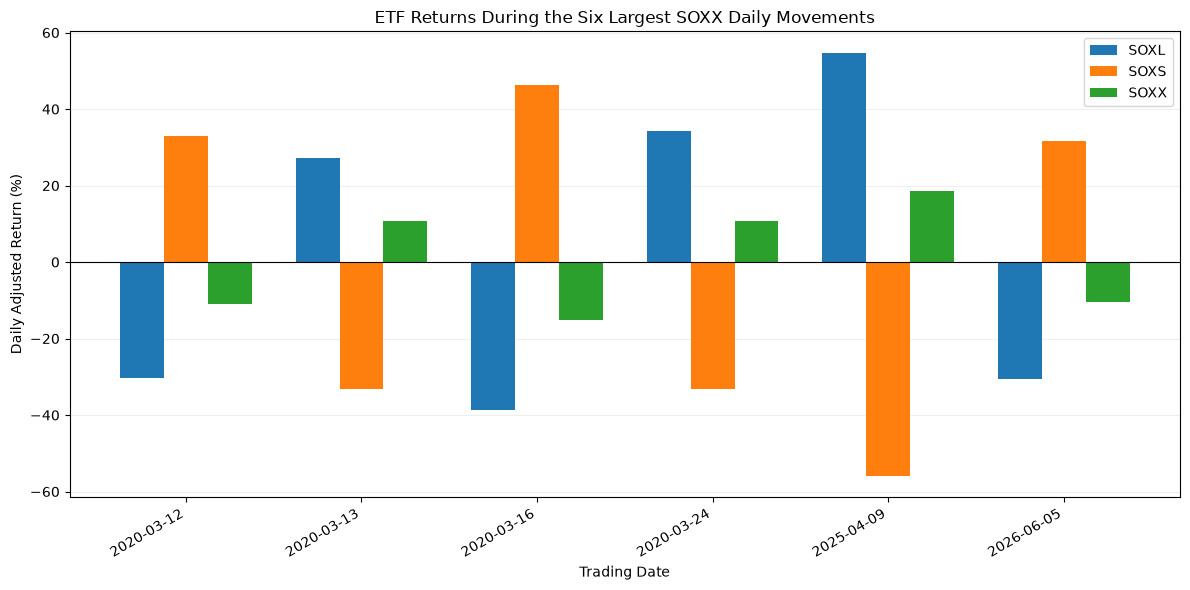

In [14]:

import matplotlib.pyplot as plt

# Calculate adjusted daily returns for all three ETFs.
return_frames = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()
    df["Date"] = pd.to_datetime(df["Date"])
    df = df.sort_values("Date")

    df[ticker] = (
        df["Adj Close"].pct_change(fill_method=None) * 100
    )

    return_frames.append(
        df.set_index("Date")[[ticker]]
    )

# Align all returns by trading date.
daily_returns = (
    pd.concat(return_frames, axis=1, join="inner")
    .dropna()
    .sort_index()
)

# Select SOXX's six largest absolute daily movements.
top_dates = (
    daily_returns["SOXX"].abs().nlargest(6).index
)

comparison = daily_returns.loc[top_dates].sort_index()

print("Returns on SOXX's six largest daily movements:")
display(comparison.round(2))

# Create a grouped bar chart.
fig, ax = plt.subplots(figsize=(12, 6))

x = list(range(len(comparison)))
width = 0.25

ax.bar(
    [i - width for i in x],
    comparison["SOXL"],
    width,
    label="SOXL"
)

ax.bar(
    x,
    comparison["SOXS"],
    width,
    label="SOXS"
)

ax.bar(
    [i + width for i in x],
    comparison["SOXX"],
    width,
    label="SOXX"
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(
    comparison.index.strftime("%Y-%m-%d"),
    rotation=30,
    ha="right"
)

ax.set_title(
    "ETF Returns During the Six Largest SOXX Daily Movements"
)

ax.set_xlabel("Trading Date")
ax.set_ylabel("Daily Adjusted Return (%)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 6.3 Findings — Cross-ETF Extreme Return Comparison

#### Observations

The comparison of SOXX's six largest absolute daily movements reveals broadly consistent directional behaviour across the three ETFs.

- **SOXL:** Generally moves in the same direction as SOXX, with substantially larger daily movements.
- **SOXS:** Generally moves in the opposite direction to SOXX.
- **SOXX:** Experiences smaller absolute movements than the two leveraged ETFs on the selected dates.

On April 9, 2025, SOXX increased by 18.57%, SOXL increased by 54.79%, and SOXS declined by 55.98%.

#### Interpretation

The observed patterns are broadly consistent with the funds' leveraged and inverse exposure to the semiconductor sector.

However, SOXX is not necessarily the exact underlying index used by the leveraged ETFs throughout the study period. Differences from three times the SOXX return therefore cannot automatically be classified as tracking errors or incorrect data.

#### Validation Outcome

**Finding:** The selected extreme returns exhibit plausible cross-ETF directional relationships.

**Limitation:** Directional consistency alone does not independently establish that all historical prices are accurate.

**Next step:** Cross-check the selected dates against the semiconductor index data retrieved from FRED.


In [15]:

# Section 6.4 — Cross-check extreme returns with FRED

fred_check = fred.copy()

# Prepare the FRED index observations.
fred_check["Date"] = pd.to_datetime(
    fred_check["observation_date"]
)

fred_check["NASDAQSOX"] = pd.to_numeric(
    fred_check["NASDAQSOX"], errors="coerce"
)

# Exclude non-trading dates before calculating returns.
fred_check = (
    fred_check.dropna(subset=["Date", "NASDAQSOX"])
    .sort_values("Date")
)

# Calculate daily percentage changes in the index.
fred_check["NASDAQSOX Return (%)"] = (
    fred_check["NASDAQSOX"].pct_change(fill_method=None) * 100
)

fred_returns = fred_check.set_index("Date")[
    "NASDAQSOX Return (%)"
]

# Compare ETF and index returns on the six selected dates.
market_check = (
    daily_returns.loc[top_dates, ["SOXL", "SOXS", "SOXX"]]
    .join(fred_returns)
    .sort_index()
)

# Measure the difference between SOXX and the index.
market_check["SOXX - NASDAQSOX (pp)"] = (
    market_check["SOXX"]
    - market_check["NASDAQSOX Return (%)"]
)

display(market_check.round(3))


,SOXL,SOXS,SOXX,NASDAQSOX Return (%),SOXX - NASDAQSOX (pp)
Date,,,,,
2020-03-12,-30.415,32.979,-10.964,-10.907,-0.057
2020-03-13,27.323,-33.067,10.728,10.929,-0.201
2020-03-16,-38.593,46.255,-15.228,-15.896,0.668
2020-03-24,34.258,-33.063,10.816,11.155,-0.339
2025-04-09,54.788,-55.976,18.572,18.735,-0.163
2026-06-05,-30.514,31.538,-10.444,-10.257,-0.187



### 6.5 Findings — Extreme Return and Index Validation

#### Summary

The extreme-return screening identified seven SOXL days and eight SOXS days with absolute adjusted returns exceeding 30%. SOXX had no days exceeding this threshold.

A grouped bar chart compared the six largest absolute SOXX movements with SOXL and SOXS on the same dates.

#### Cross-ETF Findings

- SOXL moved in the same direction as SOXX on all six selected dates.
- SOXS moved in the opposite direction on all six dates.
- Both leveraged ETFs exhibited substantially larger movements than SOXX.

#### Independent Index Comparison

The six selected observations were also compared with NASDAQSOX data from FRED.

SOXX and NASDAQSOX moved in the same direction on all six dates. The largest absolute return difference was 0.668 percentage points on March 16, 2020.

#### Important Benchmark Limitation

SOXL and SOXS changed their underlying index from the PHLX Semiconductor Sector Index to the ICE Semiconductor Index on August 25, 2021.

SOXX also changed from the PHLX Semiconductor Sector Index to the ICE Semiconductor Index in June 2021.

Therefore, NASDAQSOX is a historical underlying-index reference before the relevant changes, but only a sector proxy afterward.

#### Validation Outcome

**Finding:** The six investigated extreme-return observations are broadly consistent across the ETF and FRED datasets.

**Limitation:** Directional agreement is not independent price verification, and the FRED index is not the exact leveraged-fund benchmark throughout the historical period.

**Decision:** Retain the observations for further analysis rather than excluding large returns solely because they exceed a screening threshold.

**Status:** Internal extreme-return screening and cross-source comparison completed. Independent price-event verification and full benchmark documentation remain outstanding.

#### Sources

- NYSE Arca Regulatory Bulletin RB-21-075 (August 25, 2021)
- Direxion, *Changes Index for Semiconductor ETFs* (June 21, 2021)
- iShares SOXX fund disclosures (2026)
- Federal Reserve Bank of St. Louis, NASDAQSOX



## 7. Benchmark History and Data-Source Verification

### 7.1 Objective

Determine which semiconductor indices were tracked by the three ETFs throughout the study period and identify limitations in using NASDAQSOX as a market reference.

### Historical Benchmark Changes

| Effective Period | SOXL / SOXS Benchmark | SOXX Benchmark |
|---|---|---|
| Before 2010-10-15 | PHLX Semiconductor Sector Index | S&P North American Technology-Semiconductors Index |
| 2010-10-15 to 2021-06-20 | PHLX Semiconductor Sector Index | PHLX Semiconductor Sector Index |
| 2021-06-21 to 2021-08-24 | PHLX Semiconductor Sector Index | ICE Semiconductor Index |
| 2021-08-25 to 2023-11-02 | ICE Semiconductor Index | ICE Semiconductor Index |
| From 2023-11-03 | NYSE Semiconductor Index | NYSE Semiconductor Index |

The ICE Semiconductor Index was renamed the NYSE Semiconductor Index on November 3, 2023.

### Implications for This Project

**NASDAQSOX:** Represents the PHLX Semiconductor Sector Index. It is a historical underlying-index reference for SOXL and SOXS before August 25, 2021. Afterward, it serves as a semiconductor-sector proxy.

**SOXX:** Provides an investable semiconductor ETF comparison, but its historical benchmark changed. SOXX should not be treated as the exact benchmark for SOXL and SOXS.

**Early SOXX history:** Before October 15, 2010, the fund was known as IGW and tracked a different index. The earliest observations in the downloaded SOXX history require additional verification.

**Methodology decision:** Preserve the benchmark-change dates as metadata. Avoid treating a continuous NASDAQSOX series as the exact leveraged-fund benchmark across the entire sample.

### Primary Sources

- [iShares September 2010 SEC supplement](https://www.sec.gov/Archives/edgar/data/1100663/000119312510216355/d497.htm)
- [Direxion June 2021 SEC prospectus supplement](https://www.sec.gov/Archives/edgar/data/1424958/000119312521195149/d177232d497.htm)
- [SOXX benchmark history in SEC filing](https://www.sec.gov/Archives/edgar/data/927971/000183988226047396/bmo7421_fwp-32138.htm)


In [16]:

# Section 7.2 — Benchmark regime coverage

# Use the trading dates shared by all three ETFs.
shared_dates = pd.DatetimeIndex(sorted(common_dates))

benchmark_periods = [
    (
        "2010-03-11", "2010-10-14",
        "PHLX", "S&P North American Technology-Semiconductors",
        "Historical benchmark for SOXL/SOXS only"
    ),
    (
        "2010-10-15", "2021-06-20",
        "PHLX", "PHLX",
        "Historical benchmark for all three ETFs"
    ),
    (
        "2021-06-21", "2021-08-24",
        "PHLX", "ICE",
        "Historical benchmark for SOXL/SOXS only"
    ),
    (
        "2021-08-25", "2023-11-02",
        "ICE", "ICE",
        "Sector proxy only"
    ),
    (
        "2023-11-03", "2026-10-30",
        "NYSE", "NYSE",
        "Sector proxy only"
    )
]

coverage_results = []

for start, end, leveraged_index, soxx_index, fred_role in benchmark_periods:

    days = (
        (shared_dates >= pd.Timestamp(start)) &
        (shared_dates <= pd.Timestamp(end))
    ).sum()

    coverage_results.append({
        "Start": start,
        "End": end,
        "SOXL/SOXS Benchmark": leveraged_index,
        "SOXX Benchmark": soxx_index,
        "NASDAQSOX Role": fred_role,
        "Trading Days": days
    })

benchmark_coverage = pd.DataFrame(coverage_results)

display(benchmark_coverage)

print(
    "Total dates accounted for:",
    benchmark_coverage["Trading Days"].sum()
)

print("Expected shared dates:", len(shared_dates))

assert (
    benchmark_coverage["Trading Days"].sum()
    == len(shared_dates)
), "Benchmark periods do not cover all shared dates."


,Start,End,SOXL/SOXS Benchmark,SOXX Benchmark,NASDAQSOX Role,Trading Days
0,2010-03-11,2010-10-14,PHLX,S&P North American Technology-Semiconductors,Historical benchmark for SOXL/SOXS only,152
1,2010-10-15,2021-06-20,PHLX,PHLX,Historical benchmark for all three ETFs,2687
2,2021-06-21,2021-08-24,PHLX,ICE,Historical benchmark for SOXL/SOXS only,46
3,2021-08-25,2023-11-02,ICE,ICE,Sector proxy only,552
4,2023-11-03,2026-10-30,NYSE,NYSE,Sector proxy only,750


Total dates accounted for: 4187
Expected shared dates: 4187



### 7.3 Findings — Historical Benchmark Coverage

#### Coverage Results

All 4,187 shared ETF trading dates were assigned to one of five benchmark periods.

| Period | Trading Days | NASDAQSOX Classification |
|---|---:|---|
| 2010-03-11 to 2010-10-14 | 152 | SOXL/SOXS historical benchmark |
| 2010-10-15 to 2021-06-20 | 2,687 | Shared historical benchmark |
| 2021-06-21 to 2021-08-24 | 46 | SOXL/SOXS historical benchmark |
| 2021-08-25 to 2023-11-02 | 552 | Sector proxy |
| 2023-11-03 to 2026-10-30 | 750 | Sector proxy |

**Validation:** All 4,187 dates were accounted for, and the coverage assertion passed.

#### Implications

NASDAQSOX represents the historical underlying index for SOXL and SOXS on 2,885 trading dates. On the remaining 1,302 dates, it is treated as a sector proxy.

SOXX's first 152 shared trading dates also predate its October 15, 2010 ticker and index change from IGW.

**Decision:** Retain benchmark-period metadata and distinguish historical underlying-index observations from proxy observations.

**Limitation:** Complete date coverage does not establish the accuracy or suitability of every index value.

**Status:** Benchmark-period mapping completed. Early SOXX history and source limitations require further assessment.



### 7.4 Investigating SOXX's Historical Ticker Transition

Before October 15, 2010, the fund now known as SOXX traded under the ticker IGW and tracked the S&P North American Technology-Semiconductors Index.

On October 15, 2010, the fund changed its ticker to SOXX and began tracking the PHLX Semiconductor Sector Index.

We will inspect observations around this transition for unusual price movements.

**Objective:** Determine whether the historical price series contains an obvious discontinuity around the ticker and benchmark change.

**Limitation:** A smooth price series does not independently verify the accuracy of the original historical records.


In [17]:

# Section 7.4 — Inspect the IGW-to-SOXX transition

soxx_transition = soxx.copy()
soxx_transition["Date"] = pd.to_datetime(
    soxx_transition["Date"]
)

soxx_transition = (
    soxx_transition.sort_values("Date").reset_index(drop=True)
)

# Calculate adjusted daily returns.
soxx_transition["SOXX Return (%)"] = (
    soxx_transition["Adj Close"].pct_change(
        fill_method=None
    ) * 100
)

# Identify the historical ticker-change date.
change_date = pd.Timestamp("2010-10-15")

# Count observations before the ticker change.
before_change = (
    soxx_transition["Date"] < change_date
).sum()

print("SOXX records before ticker change:", before_change)

# Examine the surrounding trading days.
transition_window = soxx_transition.loc[
    soxx_transition["Date"].between(
        "2010-10-11", "2010-10-20"
    ),
    ["Date", "Adj Close", "SOXX Return (%)"]
].copy()

# Add FRED index returns for context.
fred_transition = fred.copy()
fred_transition["Date"] = pd.to_datetime(
    fred_transition["observation_date"]
)

fred_transition = (
    fred_transition.dropna(subset=["NASDAQSOX"])
    .sort_values("Date")
)

fred_transition["NASDAQSOX Return (%)"] = (
    fred_transition["NASDAQSOX"].pct_change(
        fill_method=None
    ) * 100
)

transition_window = transition_window.merge(
    fred_transition[["Date", "NASDAQSOX Return (%)"]],
    on="Date",
    how="left"
)

transition_window["Historical Ticker"] = (
    transition_window["Date"].apply(
        lambda date: "IGW" if date < change_date else "SOXX"
    )
)

display(
    transition_window[
        ["Date", "Historical Ticker", "Adj Close",
         "SOXX Return (%)", "NASDAQSOX Return (%)"]
    ].round(3)
)


SOXX records before ticker change: 160


,Date,Historical Ticker,Adj Close,SOXX Return (%),NASDAQSOX Return (%)
0,2010-10-11,IGW,4.520,0.776,0.720
1,2010-10-12,IGW,4.552,0.707,0.751
2,2010-10-13,IGW,4.543,-0.186,0.096
3,2010-10-14,IGW,4.532,-0.248,-0.233
4,2010-10-15,SOXX,4.551,0.415,0.645
5,2010-10-18,SOXX,4.520,-0.682,-0.714
6,2010-10-19,SOXX,4.457,-1.394,-1.396
7,2010-10-20,SOXX,4.487,0.675,0.618



### 7.5 Findings — Historical SOXX Ticker Transition

#### Results

The downloaded SOXX dataset contains 160 observations before October 15, 2010, when the fund changed its ticker from IGW to SOXX.

Of these observations, 152 fall within the shared SOXL/SOXS analysis period.

| Metric | Result |
|---|---:|
| October 14, 2010 adjusted close | 4.532 |
| October 15, 2010 adjusted close | 4.551 |
| October 15 SOXX return | +0.415% |
| October 15 NASDAQSOX return | +0.645% |

#### Interpretation

The transition date does not exhibit an obvious split-sized price discontinuity. Returns surrounding the change also show broadly similar directional movements to NASDAQSOX.

The ticker and index change itself is confirmed by Nasdaq's October 2010 announcement and the iShares prospectus supplement.

#### Methodology Decision

- Retain the predecessor-fund observations for historical continuity.
- Identify observations before October 15, 2010 as historical IGW data.
- Do not assume that pre-transition observations tracked the PHLX Semiconductor Sector Index.
- Preserve the transition date when interpreting benchmark relationships.

**Status:** Historical ticker transition documented. Price continuity passed an initial check, but independent verification of the historical price series remains outstanding.

#### Sources

- [Nasdaq Trader — Equity Trader Alert #2010-62](https://www.nasdaqtrader.com/TraderNews.aspx?id=ETA2010-62)
- [iShares SEC Prospectus Supplement — September 24, 2010](https://www.sec.gov/Archives/edgar/data/1100663/000119312510216355/d497.htm)



## 8. Independent Corporate-Action Verification

### 8.1 Objective

Compare recorded ETF stock split events against official fund announcements rather than relying exclusively on Yahoo Finance data.

### Method

For each independently confirmed event:

1. Record the official effective trading date and split ratio.
2. Retrieve the corresponding event from the downloaded ETF dataset.
3. Compare the recorded date and ratio.
4. Flag any disagreement for investigation.

This check verifies specific corporate-action records against external evidence. Events without an independently verified announcement remain outstanding.


In [18]:

# Section 8.1 — Compare recorded splits with official announcements

official_splits = pd.DataFrame([
    {
        "ETF": "SOXX",
        "Date": "2024-03-07",
        "Official Ratio": 3.0
    },
    {
        "ETF": "SOXS",
        "Date": "2026-03-05",
        "Official Ratio": 1 / 20
    },
    {
        "ETF": "SOXS",
        "Date": "2026-07-15",
        "Official Ratio": 1 / 10
    }
])

verification_results = []

for _, event in official_splits.iterrows():

    ticker = event["ETF"]
    df = datasets[ticker].copy()

    dates = pd.to_datetime(df["Date"])
    target = pd.Timestamp(event["Date"])

    matching_rows = df.loc[dates == target]

    if matching_rows.empty:
        recorded_ratio = None
        status = "MISSING EVENT"
    else:
        recorded_ratio = float(
            matching_rows.iloc[0]["Stock Splits"]
        )

        matches = (
            abs(recorded_ratio - event["Official Ratio"])
            < 1e-8
        )

        status = "MATCH" if matches else "MISMATCH"

    verification_results.append({
        "ETF": ticker,
        "Date": event["Date"],
        "Official Ratio": event["Official Ratio"],
        "Dataset Ratio": recorded_ratio,
        "Status": status
    })

corporate_action_check = pd.DataFrame(
    verification_results
)

display(corporate_action_check)

print(
    "Verified matches:",
    (corporate_action_check["Status"] == "MATCH").sum(),
    "out of",
    len(corporate_action_check)
)


,ETF,Date,Official Ratio,Dataset Ratio,Status
0,SOXX,2024-03-07,3.00,3.00,MATCH
1,SOXS,2026-03-05,0.05,0.05,MATCH
2,SOXS,2026-07-15,0.10,0.10,MATCH


Verified matches: 3 out of 3



### 8.2 Complete Split-History Cross-Check

**Objective:** Compare all 13 recorded stock splits against independently published historical records.

Two evidence levels are used:

- **Primary:** Official announcements or disclosures from Direxion and iShares.
- **Secondary:** Independent historical split databases.

Both the effective date and split ratio must match. The test also checks for extra split events in the dataset that do not appear in the reference list.

#### Sources

**Primary sources**
- [Direxion — SOXL 2021 split](https://www.direxion.com/uploads/Direxion-Announces-Forward-and-Reverse-Splits-of-Five-ETFs.pdf)
- [Direxion — SOXS 2022 split](https://www.direxion.com/uploads/Direxion-Announces-Reverse-Splits-of-Two-ETFs-DRIP-and-SOXS-2.pdf)
- [Direxion — SOXS 2024 split](https://www.direxion.com/uploads/Direxion-Announces-Reverse-Split-of-SOXS.pdf)
- [Direxion — SOXS March 2026 split](https://www.direxion.com/press-release/direxion-announces-reverse-split-of-jdst-soxs-dust-hibs)
- [Direxion — SOXS July 2026 split](https://www.direxion.com/press-release/direxion-to-split-nine-etfs)
- [iShares — SOXX 2024 prospectus](https://www.ishares.com/us/literature/prospectus/p-ishares-phlx-semiconductor-etf-3-31.pdf)

**Secondary sources**
- [SOXL historical splits — SplitHistory](https://www.splithistory.com/?symbol=soxl)
- [SOXS historical splits — ChartExchange](https://chartexchange.com/symbol/nyse-soxs/historical/splits/)

**Limitation:** Matching a secondary historical record does not provide the same level of evidence as an original fund announcement.


In [19]:

# Section 8.2 — Audit all recorded split events

# Reference dates, ratios, and evidence types.
reference_events = [
    ("SOXL", "2015-05-20", 4, "Secondary"),
    ("SOXL", "2021-03-02", 15, "Primary"),

    ("SOXS", "2011-02-24", 1/5, "Secondary"),
    ("SOXS", "2013-08-20", 1/4, "Secondary"),
    ("SOXS", "2015-05-20", 1/4, "Secondary"),
    ("SOXS", "2017-05-01", 1/5, "Secondary"),
    ("SOXS", "2019-06-28", 1/10, "Secondary"),
    ("SOXS", "2020-08-28", 1/12, "Secondary"),
    ("SOXS", "2022-03-28", 1/10, "Primary"),
    ("SOXS", "2024-04-15", 1/10, "Primary"),
    ("SOXS", "2026-03-05", 1/20, "Primary"),
    ("SOXS", "2026-07-15", 1/10, "Primary"),

    ("SOXX", "2024-03-07", 3, "Primary")
]

references = pd.DataFrame(
    reference_events,
    columns=["ETF", "Date", "Reference Ratio", "Evidence"]
)

# Extract actual split events from the local datasets.
recorded_events = []

for ticker in ["SOXL", "SOXS", "SOXX"]:
    df = datasets[ticker].copy()

    df["Date"] = pd.to_datetime(
        df["Date"]
    ).dt.strftime("%Y-%m-%d")

    df["Stock Splits"] = pd.to_numeric(
        df["Stock Splits"], errors="coerce"
    )

    for _, event in df[df["Stock Splits"] > 0].iterrows():
        recorded_events.append({
            "ETF": ticker,
            "Date": event["Date"],
            "Dataset Ratio": event["Stock Splits"]
        })

recorded = pd.DataFrame(recorded_events)

# Compare both lists, including missing or unexpected events.
audit = references.merge(
    recorded,
    on=["ETF", "Date"],
    how="outer",
    indicator=True,
    validate="one_to_one"
)

def classify_split(row):
    if row["_merge"] == "left_only":
        return "MISSING FROM DATA"
    if row["_merge"] == "right_only":
        return "UNLISTED DATA EVENT"
    if abs(row["Reference Ratio"] - row["Dataset Ratio"]) < 1e-7:
        return "MATCH"
    return "RATIO MISMATCH"

audit["Status"] = audit.apply(classify_split, axis=1)

audit = audit.drop(columns="_merge").sort_values(
    ["ETF", "Date"]
)

display(audit.reset_index(drop=True).round(6))

print(
    "Matching events:",
    (audit["Status"] == "MATCH").sum(),
    "of", len(audit)
)

print(
    "Primary-source matches:",
    ((audit["Evidence"] == "Primary") &
     (audit["Status"] == "MATCH")).sum()
)

print(
    "Secondary-source matches:",
    ((audit["Evidence"] == "Secondary") &
     (audit["Status"] == "MATCH")).sum()
)


,ETF,Date,Reference Ratio,Evidence,Dataset Ratio,Status
0,SOXL,2015-05-20,4.000000,Secondary,4.000000,MATCH
1,SOXL,2021-03-02,15.000000,Primary,15.000000,MATCH
2,SOXS,2011-02-24,0.200000,Secondary,0.200000,MATCH
3,SOXS,2013-08-20,0.250000,Secondary,0.250000,MATCH
4,SOXS,2015-05-20,0.250000,Secondary,0.250000,MATCH
5,SOXS,2017-05-01,0.200000,Secondary,0.200000,MATCH
6,SOXS,2019-06-28,0.100000,Secondary,0.100000,MATCH
7,SOXS,2020-08-28,0.083333,Secondary,0.083333,MATCH
8,SOXS,2022-03-28,0.100000,Primary,0.100000,MATCH
9,SOXS,2024-04-15,0.100000,Primary,0.100000,MATCH


Matching events: 13 of 13
Primary-source matches: 6
Secondary-source matches: 7



### 8.3 Findings — Corporate-Action Verification

#### Summary of Results

All 13 recorded stock splits matched the dates and ratios in the external reference table.

| Verification Category | Matching Events |
|---|---:|
| Primary-source references | 6 |
| Secondary-source references | 7 |
| **Total** | **13 of 13** |

No missing events, additional unlisted events, or ratio mismatches were identified.

#### Interpretation

The results strengthen confidence in the recorded stock-split history.

Six events are supported by issuer announcements from Direxion or BlackRock. The remaining seven match independently published historical split records.

The earlier split-day return checks also found no artificial split-sized discontinuities in the adjusted price history.

#### Validation Outcome

**Finding:** All 13 recorded split dates and ratios agree with the reference history.

**Decision:** Retain the recorded corporate actions. Do not apply additional split adjustments to the already adjusted historical prices.

**Limitation:** Seven events rely on secondary historical records. Individual historical dividend amounts and market prices have not all been independently verified.

**Status:** Split-history cross-check completed. Broader price and distribution verification remains a data-source limitation.



## 9. Data Provenance and Source Limitations

### 9.1 Objective

Document the original datasets used throughout this notebook and preserve sufficient information to reproduce the validation process.

### Data Sources

| Dataset | Source | Role |
|---|---|---|
| SOXL | Yahoo Finance, accessed through yfinance | Primary leveraged ETF |
| SOXS | Yahoo Finance, accessed through yfinance | Inverse leveraged ETF comparison |
| SOXX | Yahoo Finance, accessed through yfinance | Semiconductor ETF comparison |
| NASDAQSOX | Federal Reserve Economic Data (FRED) | Historical semiconductor index and sector proxy |

**Historical cutoff:** October 30, 2026.

### Why Provenance Matters

Financial data providers can revise historical prices, distributions, and corporate-action adjustments.

Reproducing an analysis therefore requires knowing which files were originally downloaded and validated.

We will record each file's coverage, observation count, and SHA-256 checksum.

A checksum is a digital fingerprint of a file. If its contents change, its checksum will almost certainly change too.

**Important:** A matching checksum establishes file identity, not the accuracy of the market data itself.


In [20]:

# Section 9.2 — Data-source inventory

import hashlib

source_files = {
    "SOXL": "soxl_yahoo_daily.csv",
    "SOXS": "soxs_yahoo_daily.csv",
    "SOXX": "soxx_yahoo_daily.csv",
    "NASDAQSOX": "nasdaqsox_fred_original.csv"
}

source_inventory = []

for name, filename in source_files.items():

    path = DATA_DIR / filename
    df = datasets[name]

    # Identify the correct date column.
    date_column = (
        "observation_date"
        if name == "NASDAQSOX"
        else "Date"
    )

    dates = pd.to_datetime(
        df[date_column], errors="coerce"
    )

    # Calculate the SHA-256 fingerprint of the original file.
    checksum = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    source_inventory.append({
        "Dataset": name,
        "File": filename,
        "First Date": dates.min().strftime("%Y-%m-%d"),
        "Last Date": dates.max().strftime("%Y-%m-%d"),
        "Rows": len(df),
        "Missing Values": int(df.isna().sum().sum()),
        "SHA-256": checksum
    })

inventory = pd.DataFrame(source_inventory)

# Display a compact overview.
display(
    inventory.drop(columns="SHA-256")
)

# Keep complete checksums for reproducibility.
print("Original file checksums:")
display(inventory[["Dataset", "SHA-256"]])


,Dataset,File,First Date,Last Date,Rows,Missing Values
0,SOXL,soxl_yahoo_daily.csv,2010-03-11,2026-10-30,4187,0
1,SOXS,soxs_yahoo_daily.csv,2010-03-11,2026-10-30,4187,0
2,SOXX,soxx_yahoo_daily.csv,2010-03-01,2026-10-30,4195,0
3,NASDAQSOX,nasdaqsox_fred_original.csv,2010-03-01,2026-10-30,4350,155


Original file checksums:


,Dataset,SHA-256
0,SOXL,787a1b47c01385df60692d8d7f4cbcca12d4c806107905...
1,SOXS,201fbd26c91f77b3e19761e724ab1bdafd5fd5258ad967...
2,SOXX,1980454d1006ecbd20c6bfd921c0ad6834939b80b28099...
3,NASDAQSOX,265cfe6f23e28b2bc1a391327ec2237d4f1275f36599da...



### 9.3 Findings — Data Provenance

#### Source Inventory

All four original data files were successfully located and inspected.

- SOXL: 4,187 observations
- SOXS: 4,187 observations
- SOXX: 4,195 observations
- NASDAQSOX: 4,350 observations, including 155 missing index values

The datasets end on October 30, 2026, consistent with the project's predefined historical cutoff.

#### File Integrity

A SHA-256 checksum was calculated for each original CSV file.

These checksums establish a reference for detecting subsequent changes to the downloaded files.

#### Methodology Decision

- Preserve the original raw CSV files.
- Retain source-file checksums for reproducibility.
- Use separately prepared datasets for future analysis.
- Do not treat matching checksums as evidence that market prices are necessarily accurate.

**Status:** Source inventory and original-file fingerprinting completed.



### 9.4 OHLC Price Consistency

#### Objective

Check whether the daily Open, High, Low, and Close values satisfy basic price relationships.

#### Validation Rules

For every ETF observation:

1. High must be greater than or equal to Open.
2. High must be greater than or equal to Close.
3. Low must be less than or equal to Open.
4. Low must be less than or equal to Close.
5. High must be greater than or equal to Low.

Adjusted Close is not included in these comparisons because historical dividend adjustments may place it on a different price basis.

We also screen for negative trading volume and report zero-volume observations separately.

**Purpose:** Identify inconsistent market records before calculating risk measures.


In [21]:

# Section 9.4 — OHLC consistency checks

ohlc_results = []
suspicious_rows = []

for ticker, original_df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    df = original_df.copy()

    # Convert market data into numerical values.
    price_cols = ["Open", "High", "Low", "Close"]

    df[price_cols] = df[price_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    df["Volume"] = pd.to_numeric(
        df["Volume"], errors="coerce"
    )

    # Check the relationships between daily prices.
    invalid_high = (
        (df["High"] < df["Open"]) |
        (df["High"] < df["Close"]) |
        (df["High"] < df["Low"])
    )

    invalid_low = (
        (df["Low"] > df["Open"]) |
        (df["Low"] > df["Close"]) |
        (df["Low"] > df["High"])
    )

    # Identify records that need investigation.
    suspicious = invalid_high | invalid_low

    flagged = df.loc[
        suspicious,
        ["Date", "Open", "High", "Low", "Close", "Volume"]
    ].copy()

    flagged.insert(0, "ETF", ticker)
    suspicious_rows.append(flagged)

    ohlc_results.append({
        "ETF": ticker,
        "Total Records": len(df),
        "Invalid High": int(invalid_high.sum()),
        "Invalid Low": int(invalid_low.sum()),
        "Rows Flagged": int(suspicious.sum()),
        "Negative Volume": int((df["Volume"] < 0).sum()),
        "Zero Volume": int((df["Volume"] == 0).sum()),
        "Missing Volume": int(df["Volume"].isna().sum())
    })

ohlc_summary = pd.DataFrame(ohlc_results)

display(ohlc_summary)

# Display records requiring investigation, if any.
flagged_rows = pd.concat(
    suspicious_rows, ignore_index=True
)

if flagged_rows.empty:
    print("No OHLC inconsistencies detected.")
else:
    print("Flagged records requiring investigation:")
    display(flagged_rows.head(20))


,ETF,Total Records,Invalid High,Invalid Low,Rows Flagged,Negative Volume,Zero Volume,Missing Volume
0,SOXL,4187,0,0,0,0,0,0
1,SOXS,4187,0,0,0,0,1986,0
2,SOXX,4195,0,0,0,0,0,0


No OHLC inconsistencies detected.



### 9.5 Findings — OHLC and Trading Volume

#### Price Consistency

All three ETF datasets passed the OHLC consistency checks.

No observations contained invalid high/low relationships, and no negative or missing trading-volume values were identified.

#### Unexpected Finding: SOXS Volume

SOXS contains 1,986 zero-volume observations out of 4,187 trading dates, representing approximately 47.4% of its history.

SOXL and SOXX contain no zero-volume observations.

This requires further investigation because zero reported volume may reflect historical data-provider limitations rather than a genuine absence of trading.

#### Validation Decision

**OHLC prices:** Initial consistency checks passed.

**SOXS trading volume:** Flagged for investigation.

**Data handling:** Preserve all original observations. Do not fill zero-volume records or remove them without establishing the reason.

**Status:** OHLC validation completed. Trading-volume validation remains open.



### 9.6 Investigating SOXS Zero-Volume Observations

#### Objective

Determine when zero-volume observations occur in SOXS's historical dataset.

#### Method

Calculate the number and percentage of zero-volume observations for each year.

Visualize the annual percentage of affected observations to identify any time-dependent patterns.

#### Investigation Questions

- Are zero-volume observations concentrated in earlier years?
- Do they continue into recent trading history?
- Are they isolated observations or part of a sustained historical data-quality issue?

The results will inform whether volume is suitable for use in later modelling.


SOXS annual zero-volume summary:


,Year,Trading_Days,Zero_Volume_Days,Zero Volume (%)
0,2010,206,206,100.00
1,2011,252,252,100.00
2,2012,250,250,100.00
3,2013,252,252,100.00
4,2014,252,252,100.00
5,2015,252,252,100.00
6,2016,252,252,100.00
7,2017,251,243,96.81
8,2018,251,27,10.76
9,2019,252,0,0.00


First zero-volume date: 2010-03-11
Last zero-volume date: 2018-08-08


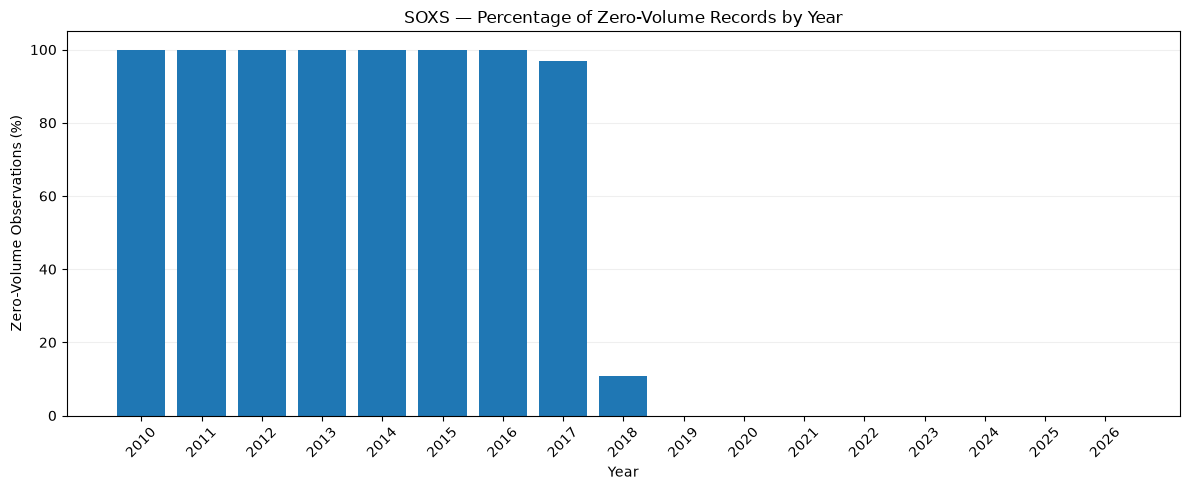

In [22]:

# Section 9.6 — Investigate SOXS zero-volume records

import matplotlib.pyplot as plt

soxs_volume = soxs.copy()

# Prepare dates and volume values.
soxs_volume["Date"] = pd.to_datetime(soxs_volume["Date"])

soxs_volume["Volume"] = pd.to_numeric(
    soxs_volume["Volume"], errors="coerce"
)

soxs_volume = soxs_volume.sort_values("Date")

# Identify zero-volume observations.
soxs_volume["Zero Volume"] = soxs_volume["Volume"] == 0
soxs_volume["Year"] = soxs_volume["Date"].dt.year

# Calculate yearly zero-volume counts.
yearly_volume = (
    soxs_volume.groupby("Year")
    .agg(
        Trading_Days=("Date", "count"),
        Zero_Volume_Days=("Zero Volume", "sum")
    )
    .reset_index()
)

# Calculate the percentage of observations affected.
yearly_volume["Zero Volume (%)"] = (
    yearly_volume["Zero_Volume_Days"]
    / yearly_volume["Trading_Days"] * 100
)

print("SOXS annual zero-volume summary:")
display(yearly_volume.round(2))

# Identify the first and last affected dates.
zero_dates = soxs_volume.loc[soxs_volume["Zero Volume"]]

print("First zero-volume date:", zero_dates["Date"].min().date())
print("Last zero-volume date:", zero_dates["Date"].max().date())

# Visualize the yearly percentage of zero-volume records.
fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    yearly_volume["Year"].astype(str),
    yearly_volume["Zero Volume (%)"]
)

ax.set_title("SOXS — Percentage of Zero-Volume Records by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Zero-Volume Observations (%)")

ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



### 9.7 Investigating Reverse-Split Effects on Historical Volume

#### Hypothesis

The concentration of zero-volume observations before August 2018 may be related to cumulative reverse-split adjustments.

Historical volume can be expressed on a split-adjusted share basis. Repeated reverse splits may reduce earlier adjusted volume values to very small numbers.

If the data provider stores or rounds adjusted volumes as whole numbers, sufficiently small values could appear as zero.

#### Method

We will:

1. Calculate the cumulative reverse-split factor occurring after each observation.
2. Compare adjustment factors across historical periods.
3. Examine volume around the last reported zero-volume date.
4. Check how frequently closing prices changed on days reporting zero volume.

**Important:** This test can support the split-adjustment explanation, but cannot establish how Yahoo Finance generated every historical volume observation.


In [23]:

# Section 9.7 — Test the reverse-split volume hypothesis

soxs_volume_check = (
    soxs_volume.copy()
    .sort_values("Date")
    .reset_index(drop=True)
)

# Calculate the inverse factor for each recorded split.
splits = pd.to_numeric(
    soxs_volume_check["Stock Splits"],
    errors="coerce"
).fillna(0)

split_factors = splits.apply(
    lambda ratio: 1 / ratio if ratio > 0 else 1.0
)

# Calculate the combined factor of all LATER splits,
# excluding any split occurring on the current date.
soxs_volume_check["Later Split Factor"] = (
    split_factors.iloc[::-1].cumprod().iloc[::-1]
    / split_factors
)

# Check whether closing prices changed on zero-volume dates.
soxs_volume_check["Close Return (%)"] = (
    soxs_volume_check["Close"].pct_change(
        fill_method=None
    ) * 100
)

zero_mask = soxs_volume_check["Volume"] == 0

price_changed = (
    zero_mask &
    soxs_volume_check["Close Return (%)"].notna() &
    (soxs_volume_check["Close Return (%)"].abs() > 0.000001)
)

print("Total zero-volume days:", zero_mask.sum())
print(
    "Zero-volume days with changing closing prices:",
    price_changed.sum()
)

# Summarize selected periods.
yearly_factors = (
    soxs_volume_check.groupby("Year")
    .agg(
        Zero_Volume_Days=("Zero Volume", "sum"),
        Median_Later_Split_Factor=(
            "Later Split Factor", "median"
        )
    )
    .reset_index()
)

display(
    yearly_factors[
        yearly_factors["Year"].isin(
            [2010, 2015, 2017, 2018, 2019, 2026]
        )
    ].style.format({
        "Median_Later_Split_Factor": "{:,.0f}"
    })
)

# Inspect observations around the last zero-volume date.
cutoff = pd.Timestamp("2018-08-08")

transition = soxs_volume_check.loc[
    soxs_volume_check["Date"].between(
        cutoff - pd.DateOffset(days=10),
        cutoff + pd.DateOffset(days=10)
    ),
    ["Date", "Volume",
     "Later Split Factor", "Close Return (%)"]
]

display(transition.round(3))


Total zero-volume days: 1986
Zero-volume days with changing closing prices: 1976


,Year,Zero_Volume_Days,Median_Later_Split_Factor
0,2010,206,"960,000,000"
5,2015,252,"12,000,000"
7,2017,243,"2,400,000"
8,2018,27,"2,400,000"
9,2019,0,"240,000"
16,2026,0,10


,Date,Volume,Later Split Factor,Close Return (%)
2111,2018-07-30,1,2400000.0,2.920
2112,2018-07-31,1,2400000.0,-2.055
2113,2018-08-01,1,2400000.0,0.599
2114,2018-08-02,1,2400000.0,-2.979
2115,2018-08-03,1,2400000.0,-0.409
2116,2018-08-06,1,2400000.0,-1.850
2117,2018-08-07,1,2400000.0,-2.408
2118,2018-08-08,0,2400000.0,-0.858
2119,2018-08-09,1,2400000.0,3.247
2120,2018-08-10,2,2400000.0,7.338



### 9.8 Findings — Historical SOXS Volume Reliability

#### Summary

The SOXS dataset contains 1,986 zero-volume observations, representing approximately 47.4% of its 4,187 trading dates.

Of these, 1,976 also show changes in closing prices.

Zero-volume observations are concentrated before August 2018. The last recorded zero-volume date is August 8, 2018.

#### Reverse-Split Investigation

Historical observations are associated with exceptionally large cumulative subsequent reverse-split factors.

For example:

| Year | Median Subsequent Split Factor | Zero-Volume Days |
|---|---:|---:|
| 2010 | 960,000,000 | 206 |
| 2015 | 12,000,000 | 252 |
| 2017 | 2,400,000 | 243 |
| 2018 | 2,400,000 | 27 |
| 2019 | 240,000 | 0 |
| 2026 | 10 | 0 |

These findings are consistent with historical split-adjusted volume values becoming extremely small.

However, Yahoo Finance's precise treatment and rounding of these observations has not been independently established.

#### Methodology Decision

**Price data:** Retain historical SOXS price observations, subject to the separate price-validation findings.

**Volume data:** Do not use early SOXS volume observations as reliable measures of actual trading activity without independent verification.

**Raw data:** Preserve all original observations. Do not replace zero-volume records with estimated values.

**Modelling implication:** Exclude the affected historical SOXS volume observations from volume-based modelling unless reliable alternative data becomes available.

#### Validation Status

**Investigated with limitations.** The volume anomaly has been characterized and a conservative treatment selected. Its exact source remains unconfirmed.

This limitation must be documented in future data preparation and modelling.



## 10. VIX — Market Volatility Data Validation 

### 10.1 Objective

Collect and validate historical observations of the Cboe Volatility Index (VIX) for use as a broader market volatility indicator in the SOXL downside-risk project.

### Why VIX Matters

VIX estimates the S&P 500's expected volatility over approximately the next 30 days using options-market prices.

Unlike historical realized volatility, which is calculated from observed price changes, VIX is a forward-looking market-implied volatility measure.

VIX is not semiconductor-specific and does not directly predict the direction of SOXL returns.

### Research Purpose

Evaluate whether broader market-implied volatility helps identify periods of elevated SOXL downside risk beyond information already available from semiconductor-market returns and historical volatility.

### Data Source

- **Provider:** Federal Reserve Economic Data (FRED)
- **Original source:** Cboe
- **Series ID:** VIXCLS
- **Frequency:** Daily close
- **Historical cutoff:** October 30, 2026

Source: https://fred.stlouisfed.org/series/VIXCLS

### Validation Plan

1. Retrieve the historical VIX series.
2. Verify dates, duplicates, missing observations, and index values.
3. Check alignment with ETF trading dates.
4. Investigate unexpected observations or gaps.
5. Record source provenance and limitations.
6. Establish rules for later use without introducing look-ahead bias.


In [24]:

# Section 10.2 — Retrieve or reuse historical VIX data

import requests
from io import BytesIO

VIX_START = "2010-03-01"
VIX_END = "2026-10-30"

vix_path = DATA_DIR / "vix_fred_original.csv"

# Preserve the original source snapshot.
if vix_path.exists():

    print("Reusing existing VIX source file.")
    raw_vix = vix_path.read_bytes()

else:

    print("Downloading VIX from FRED.")

    url = "https://fred.stlouisfed.org/graph/fredgraph.csv"

    params = {
        "id": "VIXCLS",
        "cosd": VIX_START,
        "coed": VIX_END
    }

    response = requests.get(
        url,
        params=params,
        timeout=(10, 30)
    )

    response.raise_for_status()

    raw_vix = response.content

    # Save only when the original file does not exist.
    vix_path.write_bytes(raw_vix)

# Load the preserved source data.
vix = pd.read_csv(BytesIO(raw_vix))

required_columns = {"observation_date", "VIXCLS"}

if not required_columns.issubset(vix.columns):
    raise ValueError(
        f"Unexpected FRED columns: {list(vix.columns)}"
    )

# Prepare the data for validation.
vix["observation_date"] = pd.to_datetime(
    vix["observation_date"],
    errors="coerce"
)

vix["VIXCLS"] = pd.to_numeric(
    vix["VIXCLS"],
    errors="coerce"
)

print("\nVIX source verification")
print("Total observations:", len(vix))
print("First date:", vix["observation_date"].min())
print("Last date:", vix["observation_date"].max())
print("Missing values:", vix["VIXCLS"].isna().sum())
print("Duplicate dates:",
      vix["observation_date"].duplicated().sum())
print("Invalid dates:",
      vix["observation_date"].isna().sum())
print("Nonpositive observed values:",
      (vix["VIXCLS"] <= 0).sum())
print("Original file preserved:", vix_path.relative_to(PROJECT_ROOT))

display(vix.head())


Reusing existing VIX source file.

VIX source verification
Total observations: 4350
First date: 2010-03-01 00:00:00
Last date: 2026-10-30 00:00:00
Missing values: 122
Duplicate dates: 0
Invalid dates: 0
Nonpositive observed values: 0
Original file preserved: data/raw/vix_fred_original.csv


,observation_date,VIXCLS
0,2010-03-01,19.26
1,2010-03-02,19.06
2,2010-03-03,18.83
3,2010-03-04,18.72
4,2010-03-05,17.42



### 10.3 VIX Trading-Calendar Alignment

#### Objective

Determine whether VIX observations are available on the trading dates used in our ETF analysis.

The VIX dataset contains 4,350 dated rows, of which 122 have missing index values.

Unlike the ETF datasets, the FRED series includes dates without reported index observations.

#### Method

Compare valid VIX observation dates against:

1. SOXX's complete trading calendar.
2. The 4,187 dates shared by SOXL, SOXS, and SOXX.

Identify any ETF trading dates without VIX observations and any additional VIX observation dates.

#### Data Handling

Preserve the original VIX CSV.

Do not replace missing observations with zero or assume that a missing date represents a VIX value of zero.

The results will determine how VIX should be aligned with ETF returns during later analysis.


In [25]:

# Section 10.3 — Compare VIX and ETF trading calendars

# Build the set of valid VIX observation dates.
vix_valid_dates = set(
    vix.loc[
        vix["VIXCLS"].notna(),
        "observation_date"
    ].dt.normalize()
)

# Build each ETF's trading-date set.
etf_calendars = {}

for ticker, df in {
    "SOXL": soxl,
    "SOXS": soxs,
    "SOXX": soxx
}.items():

    etf_calendars[ticker] = set(
        pd.to_datetime(df["Date"]).dt.normalize()
    )

# Dates shared by all three ETFs.
common_etf_dates = set.intersection(
    *etf_calendars.values()
)

# Find differences between VIX and the ETF calendars.
soxx_missing_vix = (
    etf_calendars["SOXX"] - vix_valid_dates
)

common_missing_vix = (
    common_etf_dates - vix_valid_dates
)

vix_only_dates = (
    vix_valid_dates - etf_calendars["SOXX"]
)

calendar_summary = pd.DataFrame({
    "Check": [
        "Valid VIX observations",
        "SOXX trading dates",
        "Common ETF trading dates",
        "SOXX dates without VIX",
        "Common ETF dates without VIX",
        "VIX dates absent from SOXX"
    ],
    "Count": [
        len(vix_valid_dates),
        len(etf_calendars["SOXX"]),
        len(common_etf_dates),
        len(soxx_missing_vix),
        len(common_missing_vix),
        len(vix_only_dates)
    ]
})

display(calendar_summary)

print("\nSOXX trading dates without VIX:")
display(sorted(soxx_missing_vix)[:20])

print("\nCommon ETF dates without VIX:")
display(sorted(common_missing_vix)[:20])

print("\nVIX observation dates absent from SOXX:")
display(sorted(vix_only_dates)[:20])


,Check,Count
0,Valid VIX observations,4228
1,SOXX trading dates,4195
2,Common ETF trading dates,4187
3,SOXX dates without VIX,0
4,Common ETF dates without VIX,0
5,VIX dates absent from SOXX,33



SOXX trading dates without VIX:


[]


Common ETF dates without VIX:


[]


VIX observation dates absent from SOXX:


[Timestamp('2022-05-30 00:00:00'),
 Timestamp('2022-06-20 00:00:00'),
 Timestamp('2022-07-04 00:00:00'),
 Timestamp('2022-09-05 00:00:00'),
 Timestamp('2022-11-24 00:00:00'),
 Timestamp('2023-01-16 00:00:00'),
 Timestamp('2023-02-20 00:00:00'),
 Timestamp('2023-05-29 00:00:00'),
 Timestamp('2023-06-19 00:00:00'),
 Timestamp('2023-07-04 00:00:00'),
 Timestamp('2023-09-04 00:00:00'),
 Timestamp('2023-11-23 00:00:00'),
 Timestamp('2024-01-15 00:00:00'),
 Timestamp('2024-02-19 00:00:00'),
 Timestamp('2024-05-27 00:00:00'),
 Timestamp('2024-06-19 00:00:00'),
 Timestamp('2024-07-04 00:00:00'),
 Timestamp('2024-09-02 00:00:00'),
 Timestamp('2024-11-28 00:00:00'),
 Timestamp('2025-01-09 00:00:00')]


### 10.4 Independent VIX Source Verification

#### Objective

Investigate the 33 VIX observation dates absent from the SOXX trading calendar and compare FRED's reported closing levels with the original Cboe historical dataset.

#### Method

1. Retrieve Cboe's published historical VIX prices.
2. Compare its available dates with the FRED VIX series.
3. Determine whether the 33 additional FRED observations appear in the Cboe dataset.
4. Compare closing values on dates shared by both providers.

#### Validation Principle

Agreement between FRED and the ETF trading calendar does not establish that the VIX values themselves are accurate.

An independent source comparison is needed before selecting VIX as a modelling input.

Source: https://www.cboe.com/tradable-products/vix/vix-historical-data


In [26]:

# Section 10.4 — Verify VIX against the preserved Cboe source

from io import BytesIO
import requests

cboe_url = (
    "https://cdn-api.cboe.com/api/global/"
    "us_indices/daily_prices/VIX_History.csv"
)

cboe_path = DATA_DIR / "vix_cboe_original.csv"

# Preserve the original downloaded Cboe snapshot.
if cboe_path.exists():

    print("Reusing existing Cboe VIX reference file.")
    cboe_bytes = cboe_path.read_bytes()

else:

    print("Downloading historical VIX data from Cboe.")

    cboe_response = requests.get(
        cboe_url,
        timeout=(10, 30)
    )
    cboe_response.raise_for_status()

    cboe_bytes = cboe_response.content

    # Save only if the source file does not already exist.
    cboe_path.write_bytes(cboe_bytes)

# Load the preserved Cboe data.
cboe_vix = pd.read_csv(BytesIO(cboe_bytes))

required_columns = {"DATE", "CLOSE"}

if not required_columns.issubset(cboe_vix.columns):
    raise ValueError(
        f"Unexpected Cboe columns: {list(cboe_vix.columns)}"
    )

cboe_vix["Date"] = pd.to_datetime(
    cboe_vix["DATE"],
    errors="coerce"
).dt.normalize()

cboe_vix["Cboe Close"] = pd.to_numeric(
    cboe_vix["CLOSE"],
    errors="coerce"
)

# Prepare FRED data for comparison.
fred_vix = vix.rename(
    columns={
        "observation_date": "Date",
        "VIXCLS": "FRED Close"
    }
).copy()

fred_vix["Date"] = (
    pd.to_datetime(fred_vix["Date"]).dt.normalize()
)

# Match FRED and Cboe records by date.
comparison = fred_vix.merge(
    cboe_vix[["Date", "Cboe Close"]],
    on="Date",
    how="outer",
    validate="one_to_one"
)

comparison["Absolute Difference"] = (
    comparison["FRED Close"] -
    comparison["Cboe Close"]
).abs()

# Investigate VIX dates absent from SOXX.
extra_dates = comparison[
    comparison["Date"].isin(vix_only_dates)
].copy()

print("\nVIX dates absent from SOXX:", len(extra_dates))

print("\nComparison on additional dates:")
display(
    extra_dates[
        ["Date", "FRED Close", "Cboe Close"]
    ].sort_values("Date")
)

# Compare source values on common ETF trading dates.
shared_market_dates = comparison[
    comparison["Date"].isin(common_etf_dates)
].copy()

print("\nCommon ETF dates:", len(shared_market_dates))

print(
    "Dates missing a Cboe value:",
    shared_market_dates["Cboe Close"].isna().sum()
)

print(
    "Maximum absolute closing-value difference:",
    shared_market_dates["Absolute Difference"].max()
)

print("\nTen largest source discrepancies:")
display(
    shared_market_dates.nlargest(
        10, "Absolute Difference"
    )[
        ["Date", "FRED Close",
         "Cboe Close", "Absolute Difference"]
    ]
)

print("\nOriginal Cboe reference preserved:", cboe_path.relative_to(PROJECT_ROOT))


Reusing existing Cboe VIX reference file.

VIX dates absent from SOXX: 33

Comparison on additional dates:


,Date,FRED Close,Cboe Close
8273,2022-05-30,26.54,26.54
8288,2022-06-20,31.03,31.03
8298,2022-07-04,27.53,27.53
8343,2022-09-05,25.99,25.99
8401,2022-11-24,20.42,20.42
8438,2023-01-16,19.49,19.49
8463,2023-02-20,21.23,21.23
8533,2023-05-29,17.46,17.46
8548,2023-06-19,14.19,14.19
8559,2023-07-04,13.70,13.70



Common ETF dates: 4187
Dates missing a Cboe value: 0
Maximum absolute closing-value difference: 0.0

Ten largest source discrepancies:


,Date,FRED Close,Cboe Close,Absolute Difference
5086,2010-03-11,18.06,18.06,0.0
5087,2010-03-12,17.58,17.58,0.0
5088,2010-03-15,18.00,18.00,0.0
5089,2010-03-16,17.69,17.69,0.0
5090,2010-03-17,16.91,16.91,0.0
5091,2010-03-18,16.62,16.62,0.0
5092,2010-03-19,16.97,16.97,0.0
5093,2010-03-22,16.87,16.87,0.0
5094,2010-03-23,16.35,16.35,0.0
5095,2010-03-24,17.55,17.55,0.0



Original Cboe reference preserved: data/raw/vix_cboe_original.csv



### 10.5 Findings — VIX Source Verification

#### Summary

The FRED VIX series was compared against Cboe's published historical VIX closing values to assess source consistency and trading-calendar alignment.

| Validation Check | Result |
|---|---:|
| Common ETF dates compared | 4,187 |
| ETF dates missing a Cboe value | 0 |
| Maximum absolute closing-value difference | 0.00 |
| Additional VIX dates absent from SOXX | 33 |

All 4,187 common ETF trading dates contain matching FRED and Cboe VIX closing values.

#### Additional Calendar Observations

The VIX dataset contains 33 valid observations on dates absent from SOXX's trading calendar.

All 33 observations fall on U.S. stock-market closure dates, beginning on May 30, 2022. These include regularly scheduled market holidays and the special NYSE closure on January 9, 2025, for the national day of mourning following former President Jimmy Carter's death.

These dates have reported VIX closing values despite having no corresponding SOXX trading observations.

The additional observations also appear in Cboe's published historical dataset, with matching closing values.

**Interpretation:** The additional dates reflect differences between the published VIX observation calendar and the SOXX trading calendar. Their presence does not indicate missing SOXX prices or establish that ordinary U.S. equity trading occurred on those dates.

#### Methodology Decision

- Retain the original FRED VIX file unchanged.
- Preserve the Cboe reference dataset for reproducibility.
- Align VIX with ETF observations using trading dates.
- Exclude VIX-only dates from ETF-based daily modelling without deleting them from the original source files.
- Do not fill missing values with zeros.
- Preserve the additional VIX observations for source verification and calendar analysis.
- Treat VIX as a candidate market-implied volatility indicator, not as a semiconductor-specific volatility measure.

#### Validation Outcome

**Finding:** Complete agreement between FRED and Cboe closing values on all 4,187 common ETF trading dates.

**Calendar finding:** All 33 additional VIX observations absent from SOXX's trading calendar fall on U.S. stock-market closure dates beginning May 30, 2022, including regularly scheduled holidays and one special closure.

**Limitation:** FRED republishes Cboe data, so matching values establish cross-provider consistency rather than independent verification of the underlying VIX calculation.

**Status:** VIX calendar alignment and cross-provider closing-value verification completed.



### 10.6 VIX Numerical Integrity and Extreme-Value Screening

#### Objective

Inspect the numerical range, distribution, and largest daily changes in VIX on the common ETF trading calendar.

#### Method

1. Confirm that all aligned VIX closing values are present and positive.
2. Calculate minimum, median, maximum, and upper percentiles.
3. Identify the ten highest VIX closing levels.
4. Identify the ten largest absolute daily changes in VIX index points.

VIX is an annualized implied-volatility index. Its daily changes are measured here in index points, not as SOXL-style investment returns.

Large VIX movements will be investigated rather than automatically removed.


In [27]:

# Section 10.6 — VIX Numerical Integrity and Extreme-Value Screening

import hashlib

# ---------------------------------------------------------
# 1. Verify that the original VIX source files are preserved
# ---------------------------------------------------------

assert vix_path.exists(), "Missing FRED VIX source file"
assert cboe_path.exists(), "Missing Cboe VIX source file"

# Calculate SHA-256 fingerprints without modifying either file.
for label, path in {
    "FRED VIX": vix_path,
    "Cboe VIX": cboe_path
}.items():

    checksum = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    print(f"{label} SHA-256: {checksum}")


# ---------------------------------------------------------
# 2. Prepare VIX data for numerical validation
# ---------------------------------------------------------

# Restrict the audit to dates shared by all three ETFs.
vix_analysis = (
    comparison.loc[
        comparison["Date"].isin(common_etf_dates),
        ["Date", "FRED Close", "Cboe Close"]
    ]
    .sort_values("Date")
    .reset_index(drop=True)
    .copy()
)


# ---------------------------------------------------------
# 3. Validate coverage and numerical integrity
# ---------------------------------------------------------

# Confirm that all 4,187 common ETF dates are represented.
assert len(vix_analysis) == 4187, (
    "Unexpected number of aligned VIX observations"
)

# Confirm there are no duplicate dates.
assert vix_analysis["Date"].is_unique, (
    "Duplicate dates detected"
)

# Confirm there are no missing VIX values.
assert vix_analysis["FRED Close"].notna().all(), (
    "Missing FRED VIX values detected"
)

assert vix_analysis["Cboe Close"].notna().all(), (
    "Missing Cboe VIX values detected"
)

# Confirm all VIX values are positive.
assert (vix_analysis["FRED Close"] > 0).all(), (
    "Nonpositive VIX values detected"
)

# Confirm that FRED and Cboe closing values agree.
assert (
    vix_analysis["FRED Close"]
    .sub(vix_analysis["Cboe Close"])
    .abs()
    .max() < 1e-10
), "FRED and Cboe closing values do not match"


# ---------------------------------------------------------
# 4. Calculate daily VIX changes
# ---------------------------------------------------------

# VIX changes are measured in index points,
# not as percentage investment returns.
vix_analysis["Daily Change (points)"] = (
    vix_analysis["FRED Close"].diff()
)


# ---------------------------------------------------------
# 5. Summarize the VIX distribution
# ---------------------------------------------------------

vix_summary = pd.DataFrame({
    "Metric": [
        "Observations",
        "Minimum VIX",
        "Median VIX",
        "Mean VIX",
        "95th percentile",
        "99th percentile",
        "Maximum VIX",
        "Largest absolute daily change (points)"
    ],
    "Value": [
        len(vix_analysis),
        vix_analysis["FRED Close"].min(),
        vix_analysis["FRED Close"].median(),
        vix_analysis["FRED Close"].mean(),
        vix_analysis["FRED Close"].quantile(0.95),
        vix_analysis["FRED Close"].quantile(0.99),
        vix_analysis["FRED Close"].max(),
        vix_analysis["Daily Change (points)"].abs().max()
    ]
})

print("\nVIX numerical summary:")
display(vix_summary.round(2))


# ---------------------------------------------------------
# 6. Identify the ten highest VIX closing levels
# ---------------------------------------------------------

print("\nTen highest VIX closing levels:")

display(
    vix_analysis.nlargest(
        10, "FRED Close"
    )[
        ["Date", "FRED Close"]
    ]
)


# ---------------------------------------------------------
# 7. Identify the ten largest daily VIX movements
# ---------------------------------------------------------

largest_changes = (
    vix_analysis
    .assign(
        Absolute_Change=lambda df:
        df["Daily Change (points)"].abs()
    )
    .nlargest(10, "Absolute_Change")
)

print("\nTen largest absolute daily VIX changes:")

display(
    largest_changes[
        ["Date", "FRED Close", "Daily Change (points)"]
    ].round(2)
)


# ---------------------------------------------------------
# 8. Final validation confirmation
# ---------------------------------------------------------

print("\nVIX numerical integrity checks passed.")
print("Original FRED and Cboe source files remain unchanged.")


FRED VIX SHA-256: 81ece32de64b7bf047a61e144a8b2162aa0a80439a5c8c56a0b871717c86eea3
Cboe VIX SHA-256: 0fbd2010663102746b54b12bf96ab0ca4add0c922aebc4dabb0a84cd9c8b0e63

VIX numerical summary:


,Metric,Value
0,Observations,4187.00
1,Minimum VIX,9.14
2,Median VIX,16.65
3,Mean VIX,18.37
4,95th percentile,31.19
5,99th percentile,41.18
6,Maximum VIX,82.69
7,Largest absolute daily change (points),24.86



Ten highest VIX closing levels:


,Date,FRED Close
2520,2020-03-16,82.69
2522,2020-03-18,76.45
2521,2020-03-17,75.91
2518,2020-03-12,75.47
2523,2020-03-19,72.00
2524,2020-03-20,66.04
2529,2020-03-27,65.54
2527,2020-03-25,63.95
2526,2020-03-24,61.67
2525,2020-03-23,61.59



Ten largest absolute daily VIX changes:


,Date,FRED Close,Daily Change (points)
2520,2020-03-16,82.69,24.86
2518,2020-03-12,75.47,21.57
1990,2018-02-05,37.32,20.01
3794,2025-04-09,33.62,-18.71
2519,2020-03-13,57.83,-17.64
356,2011-08-08,48.00,16.00
3791,2025-04-04,45.31,15.29
3624,2024-08-05,38.57,15.18
2739,2021-01-27,37.21,14.19
2581,2020-06-11,40.79,13.22



VIX numerical integrity checks passed.
Original FRED and Cboe source files remain unchanged.


### 10.7 Findings — VIX Numerical Integrity

#### Summary of Results

The VIX dataset passed the numerical integrity checks on all 4,187 common ETF trading dates.

All aligned VIX values were present and positive. No duplicate dates or mismatches between FRED and Cboe closing values were identified.

#### Distribution

| Statistic | VIX Value |
|---|---:|
| Minimum | 9.14 |
| Median | 16.65 |
| Mean | 18.37 |
| 95th percentile | 31.19 |
| 99th percentile | 41.18 |
| Maximum | 82.69 |
| Largest absolute daily change | 24.86 points |

VIX measures annualized market-implied volatility for the S&P 500. Its level is not a prediction of SOXL's daily percentage return.

#### Extreme-Value Investigation

The ten highest VIX closing levels occurred during March 2020, coinciding with the COVID-19 market crisis.

The maximum value was 82.69 on March 16, 2020.

Other large daily movements occurred during periods of substantial financial-market volatility, including February 2018, August 2011, and April 2025.

On April 9, 2025, VIX fell 18.71 index points. This coincided with a large positive return in SOXL identified during the earlier extreme-return investigation.

These observations are plausible market-stress events rather than automatic data errors.

Furthermore, all aligned closing values agree with Cboe's published historical series.

#### Methodology Decision

**Data retention:** Keep the extreme VIX observations. Do not remove or cap values solely because they are historically unusual.

**Source selection:** Use FRED's VIXCLS series as the primary VIX dataset, with Cboe's published history retained as a reference.

**Alignment:** Use only VIX observations corresponding to ETF trading dates for daily ETF analysis.

**Modelling:** Treat VIX as a candidate explanatory variable alongside semiconductor-specific historical volatility.

**Look-ahead prevention:** A VIX closing observation may only be used for predictions made after that closing value was available.

**Model evaluation:** Test whether adding VIX improves out-of-sample downside-risk estimates rather than assuming it provides useful predictive information.

#### Limitations

- VIX measures S&P 500 implied volatility, not semiconductor-specific volatility.
- FRED republishes Cboe data, so source agreement is not fully independent verification of the underlying index calculation.
- Extreme observations have not all been corroborated against separate market-event records.
- VIX's predictive usefulness for SOXL has not yet been established.

#### Validation Outcome

**Result:** Numerical integrity and cross-provider closing-value checks passed.

**Assessment:** VIX is suitable for inclusion as a candidate market-volatility indicator, subject to the documented limitations.

**Status:** VIX data validation completed. Data-pipeline integration and final project documentation remain outstanding.


### 10.8 Five-Source Data Collection Pipeline Verification

#### Objective

Verify that the updated data-collection script recognizes all five primary datasets and preserves the original validated source files.

The script must reuse existing raw CSV snapshots, record their SHA-256 checksums, and update the source manifest without silently replacing historical data.

The Cboe VIX dataset is retained as a verification reference rather than counted as a sixth primary modelling dataset.


In [28]:
# Section 10.8 — Verify the five-source collection pipeline

import runpy
from pathlib import Path

script_path = Path.cwd() / "check_data.py"

if not script_path.exists():
    raise FileNotFoundError(
        f"Cannot find collection script: {script_path}"
    )

# Execute the collection script.
# The semicolon suppresses Jupyter's display
# of the large dictionary returned by runpy.
runpy.run_path(
    str(script_path),
    run_name="__main__"
);


Reusing existing SOXL Yahoo Finance snapshot (not overwritten)...
  SOXL: 4,187 records | 2010-03-11 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 2
    File: data/raw/soxl_yahoo_daily.csv

Reusing existing SOXS Yahoo Finance snapshot (not overwritten)...
  SOXS: 4,187 records | 2010-03-11 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 10
    File: data/raw/soxs_yahoo_daily.csv

Reusing existing SOXX Yahoo Finance snapshot (not overwritten)...
  SOXX: 4,195 records | 2010-03-01 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 1
    File: data/raw/soxx_yahoo_daily.csv

Reusing existing FRED NASD

### 10.8.1 Isolated Five-Source Download Test

#### Objective

Verify that `check_data.py` can retrieve all five primary historical datasets when no source files already exist.

#### Method

Run a copy of the collection script in an isolated temporary directory.

Confirm that:

1. All five primary datasets are downloaded.
2. Each dataset is recorded in the source manifest.
3. No collection errors are reported.
4. Every downloaded source file exists.
5. The original validated source files remain unchanged.

The temporary test files are deleted automatically afterward.

**Purpose:** Verify that a new user can reproduce the initial data-collection process without requiring our existing local CSV snapshots.

In [29]:

# Section 10.8.1 — Test five-source downloads in isolation

import tempfile
import subprocess
import shutil
import sys
import json
import hashlib
from pathlib import Path

project_root = Path.cwd()
script_path = project_root / "check_data.py"
original_raw = project_root / "data" / "raw"

assert script_path.exists(), "Collection script not found."

# Record checksums before the test.
original_checksums_before = {
    p.name: hashlib.sha256(p.read_bytes()).hexdigest()
    for p in original_raw.glob("*.csv")
}

# Create a separate temporary project.
with tempfile.TemporaryDirectory(
    prefix="soxl_download_test_"
) as temp_dir:

    test_root = Path(temp_dir)
    test_script = test_root / "check_data.py"

    shutil.copy2(script_path, test_script)

    print("Testing fresh downloads in an isolated directory.")

    # Run a copy of the script with no existing data files.
    result = subprocess.run(
        [sys.executable, str(test_script)],
        cwd=test_root,
        capture_output=True,
        text=True,
        timeout=360
    )

    print("\nCollection script output:")
    print(result.stdout)

    if result.stderr.strip():
        print("\nProvider messages or warnings:")
        print(result.stderr[-2000:])

    # Load the temporary source manifest.
    test_manifest_path = test_root / "data" / "manifest.json"

    assert test_manifest_path.exists(), (
        "Fresh-download manifest was not created."
    )

    test_manifest = json.loads(
        test_manifest_path.read_text(encoding="utf-8")
    )

    expected_sources = {
        "SOXL",
        "SOXS",
        "SOXX",
        "FRED_NASDAQSOX",
        "FRED_VIXCLS"
    }

    downloaded_sources = test_manifest.get("sources", {})
    collection_errors = test_manifest.get("errors", {})

    print("\nFresh-download verification:")
    print("Process exit code:", result.returncode)
    print("Primary sources:", len(downloaded_sources))
    print("Collection errors:", collection_errors)

    all_files_exist = all(
        (test_root / source["file"]).exists()
        for source in downloaded_sources.values()
    )

    all_new_downloads = all(
        source.get("file_status") == "new_download"
        for source in downloaded_sources.values()
    )

    print("All downloaded files exist:", all_files_exist)
    print("All marked as new downloads:", all_new_downloads)

# The temporary directory has now been deleted.

# Confirm that our validated data remains unchanged.
original_checksums_after = {
    p.name: hashlib.sha256(p.read_bytes()).hexdigest()
    for p in original_raw.glob("*.csv")
}

originals_unchanged = (
    original_checksums_before == original_checksums_after
)

print("\nOriginal validated files unchanged:",
      originals_unchanged)

assert originals_unchanged, (
    "Original source files unexpectedly changed."
)

assert result.returncode == 0
assert set(downloaded_sources) == expected_sources
assert not collection_errors
assert all_files_exist
assert all_new_downloads

print("\nIsolated five-source download test PASSED.")


Testing fresh downloads in an isolated directory.

Collection script output:

Fetching SOXL from Yahoo Finance using yfinance...
  SOXL: 4,187 records | 2010-03-11 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 2
    File: data/raw/soxl_yahoo_daily.csv

Fetching SOXS from Yahoo Finance using yfinance...
  SOXS: 4,187 records | 2010-03-11 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 10
    File: data/raw/soxs_yahoo_daily.csv

Fetching SOXX from Yahoo Finance using yfinance...
  SOXX: 4,195 records | 2010-03-01 to 2026-10-30
    Duplicate dates: 0 | Bad dates: 0
    Columns: Date, Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits, Capital Gains
    Split events returned: 1
    File: data/raw/soxx_yahoo_daily

### 10.9 Consolidated Five-Source Inventory

#### Objective

Consolidate the five primary datasets into a final source inventory and verify that the original data snapshots remain consistent with the collection manifest.

#### Primary Sources

1. SOXL — Yahoo Finance
2. SOXS — Yahoo Finance
3. SOXX — Yahoo Finance
4. NASDAQSOX — FRED
5. VIXCLS — FRED

The Cboe VIX dataset is retained as an additional verification reference rather than a sixth primary modelling source.

#### Verification Method

For each primary dataset:

- Confirm the original CSV exists.
- Record observation count and historical coverage.
- Record missing values.
- Calculate its SHA-256 checksum.
- Compare the checksum against the collection manifest.

The resulting inventory will establish which source snapshots were used during Notebook 01's validation.

**Limitation:** Matching checksums establish that files are unchanged relative to the recorded fingerprints. They do not independently establish the accuracy of the financial data.

In [30]:
# Section 10.9 — Consolidated Five-Source Inventory

import hashlib
import json
import pandas as pd

# ---------------------------------------------------------
# 1. Define the five primary source files
# ---------------------------------------------------------

source_specs = {
    "SOXL": ("soxl_yahoo_daily.csv", "Date"),
    "SOXS": ("soxs_yahoo_daily.csv", "Date"),
    "SOXX": ("soxx_yahoo_daily.csv", "Date"),
    "NASDAQSOX": (
        "nasdaqsox_fred_original.csv",
        "observation_date"
    ),
    "VIXCLS": (
        "vix_fred_original.csv",
        "observation_date"
    )
}


# ---------------------------------------------------------
# 2. Generate the final source inventory
# ---------------------------------------------------------

final_records = []

for name, (filename, date_col) in source_specs.items():

    path = DATA_DIR / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Missing primary source: {path}"
        )

    df = pd.read_csv(path)

    dates = pd.to_datetime(
        df[date_col],
        errors="coerce"
    )

    checksum = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    final_records.append({
        "Dataset": name,
        "File": filename,
        "Rows": len(df),
        "First Date": dates.min().strftime("%Y-%m-%d"),
        "Last Date": dates.max().strftime("%Y-%m-%d"),
        "Missing Values": int(df.isna().sum().sum()),
        "SHA-256": checksum
    })

final_inventory = pd.DataFrame(final_records)

print("Consolidated five-source inventory:")

display(
    final_inventory.drop(columns="SHA-256")
)


# ---------------------------------------------------------
# 3. Verify against the collection manifest
# ---------------------------------------------------------

manifest_path = DATA_DIR.parent / "manifest.json"

if not manifest_path.exists():
    raise FileNotFoundError(
        "Collection manifest was not found."
    )

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

manifest_sources = manifest.get("sources", {})

manifest_checksums = {
    source.get("sha256")
    for source in manifest_sources.values()
    if isinstance(source, dict)
}

final_inventory["Manifest Match"] = (
    final_inventory["SHA-256"].isin(
        manifest_checksums
    )
)

display(
    final_inventory[
        ["Dataset", "Manifest Match"]
    ]
)

assert len(final_inventory) == 5
assert len(manifest_sources) == 5
assert final_inventory["Manifest Match"].all(), (
    "One or more source checksums differ from the manifest."
)

assert not manifest.get("errors"), (
    "The collection manifest reports errors."
)


# ---------------------------------------------------------
# 4. Verify original four-file fingerprints
# ---------------------------------------------------------

original_checksums = inventory.set_index(
    "Dataset"
)["SHA-256"]

for name in ["SOXL", "SOXS", "SOXX", "NASDAQSOX"]:

    current_checksum = final_inventory.loc[
        final_inventory["Dataset"] == name,
        "SHA-256"
    ].iloc[0]

    assert current_checksum == original_checksums[name], (
        f"Original source changed: {name}"
    )

print("\nOriginal four source fingerprints unchanged.")


# ---------------------------------------------------------
# 5. Verify the Cboe reference remains available
# ---------------------------------------------------------

assert cboe_path.exists(), (
    "Cboe reference file is missing."
)

print("Cboe reference file preserved.")

print("\nFinal validation:")
print("Primary datasets:", len(final_inventory))
print("Manifest checksum matches:",
      final_inventory["Manifest Match"].sum())
print("Collection errors:", len(manifest.get("errors", {})))

print("\nFive-source inventory verification passed.")

Consolidated five-source inventory:


,Dataset,File,Rows,First Date,Last Date,Missing Values
0,SOXL,soxl_yahoo_daily.csv,4187,2010-03-11,2026-10-30,0
1,SOXS,soxs_yahoo_daily.csv,4187,2010-03-11,2026-10-30,0
2,SOXX,soxx_yahoo_daily.csv,4195,2010-03-01,2026-10-30,0
3,NASDAQSOX,nasdaqsox_fred_original.csv,4350,2010-03-01,2026-10-30,155
4,VIXCLS,vix_fred_original.csv,4350,2010-03-01,2026-10-30,122


,Dataset,Manifest Match
0,SOXL,True
1,SOXS,True
2,SOXX,True
3,NASDAQSOX,True
4,VIXCLS,True



Original four source fingerprints unchanged.
Cboe reference file preserved.

Final validation:
Primary datasets: 5
Manifest checksum matches: 5
Collection errors: 0

Five-source inventory verification passed.



## 11. Final Data Quality Assessment

### 11.1 Purpose

This section consolidates the data-quality findings for the SOXL Risk Analysis Project (Version 2.2).

Five primary datasets were evaluated:

1. SOXL — leveraged semiconductor ETF
2. SOXS — inverse leveraged semiconductor ETF
3. SOXX — unleveraged semiconductor ETF
4. NASDAQSOX — historical semiconductor index and sector proxy
5. VIXCLS — S&P 500 options-implied volatility index

A sixth file, Cboe's official historical VIX dataset, was retained as a reference for validating VIX closing values.

The historical analysis covers March 2010 through October 30, 2026.

The objective is to determine which data components can support downstream risk analysis, which require restrictions, and which limitations remain unresolved.

### 11.2 Consolidated Validation Results

| Validation Area | Key Finding | Status |
|---|---|---|
| Data acquisition | All five primary datasets available | Passed |
| Existing-file collection | All five original source files successfully reused | Passed |
| Fresh-download reproducibility | All five sources downloaded in an isolated environment | Passed |
| Source preservation | Original validated CSV snapshots remained unchanged | Passed |
| Source provenance | Five manifest checksums match | Passed |
| ETF trading calendars | 4,187 shared trading dates | Passed |
| Missing ETF prices | No missing price values | Passed |
| Price integrity | No nonpositive observed prices | Passed |
| OHLC consistency | No invalid high/low relationships | Passed |
| Stock splits | All 13 recorded events match reference history | Passed with limitations |
| Dividend adjustments | Adjusted-return calculations internally consistent | Passed with limitations |
| Extreme ETF returns | Screened and compared across sources | Retain with limitations |
| NASDAQSOX coverage | 155 missing values, consistent with trading-calendar alignment | Passed |
| Benchmark history | Historical benchmark transitions documented | Passed with limitations |
| SOXS historical volume | 1,986 zero-volume observations | Restricted use |
| VIX coverage | 4,350 rows, including 122 missing values | Passed |
| VIX trading alignment | Available on all 4,187 shared ETF trading dates | Passed |
| VIX source comparison | FRED and Cboe values match on all shared ETF dates | Passed |
| VIX numerical integrity | Positive values and plausible extreme observations | Passed |
| Independent verification of all ETF prices | Not completed for every observation | Outstanding |
| Licensing and redistribution review | Additional review required before external data publication | Outstanding |
| Final five-source notebook execution | All cells executed successfully from a fresh kernel | Passed |

### 11.3 Final Methodology Decisions

#### A. ETF Price and Return Data

Use `Adj Close` as the primary historical ETF price series for calculating daily returns and downside-risk measures.

Earlier validation confirmed that adjusted-price returns closely match the dividend-adjustment formula implied by Yahoo Finance's historical adjustment convention.

The largest observed discrepancy in the tested dividend adjustments was approximately 0.000067 percentage points.

**Decisions:**

- Calculate daily returns from `Adj Close`.
- Do not apply stock-split adjustments a second time.
- Do not add dividends again to returns already calculated from `Adj Close`.
- Preserve `Close`, `Dividends`, and `Stock Splits` for supporting analysis.
- Retain extreme returns unless a specific error is established.

The adjusted-price series passed internal consistency checks, but this does not constitute independent verification of every historical market price.

#### B. Corporate Actions

The datasets contain 13 recorded stock splits:

- SOXL: 2 forward splits
- SOXS: 10 reverse splits
- SOXX: 1 forward split

All 13 dates and ratios matched the external reference table.

Six events were classified as primary-source matches and seven as secondary-source matches.

Split-day return checks identified no artificial split-sized discontinuities.

Historical SOXS distributions were also examined using cumulative reverse-split factors.

**Decision:** Retain the existing split-adjusted historical price series.

**Limitation:** Some corporate-action evidence relies on secondary sources, and individual historical distributions have not all been independently verified.

#### C. Trading-Date Alignment

SOXL and SOXS each contain 4,187 trading observations, while SOXX contains 4,195.

All three ETFs share 4,187 trading dates from March 11, 2010 through October 30, 2026.

**Decisions:**

- Align datasets using trading dates rather than row positions.
- Use the common trading calendar for three-ETF comparisons.
- Preserve SOXX's eight additional earlier observations in the original source.
- Do not invent missing ETF observations.

The number of usable return or forward-outcome observations may be smaller than 4,187 because return calculations and prediction horizons require additional observations.

#### D. Historical Semiconductor Benchmark

NASDAQSOX provides historical PHLX Semiconductor Sector Index data.

The leveraged ETFs and SOXX experienced benchmark changes during the study period.

**Decisions:**

- Treat NASDAQSOX as the historical underlying-index reference for SOXL and SOXS before August 25, 2021.
- Treat NASDAQSOX as a semiconductor-sector proxy after the leveraged ETFs changed benchmarks.
- Preserve the separately documented SOXX benchmark history.
- Retain benchmark regime classifications for later analysis.

Historical SOXX observations before October 15, 2010 must also be identified as predecessor IGW history rather than described as originally trading under the SOXX ticker.

**Limitation:** NASDAQSOX is not the exact underlying index for every fund throughout the sample.

#### E. Historical SOXS Trading Volume

The SOXS dataset contains 1,986 zero-volume observations.

Of these, 1,976 also show changes in reported closing prices.

The zero-volume observations are concentrated before August 2018, with the final affected date occurring on August 8, 2018.

Subsequent reverse-split factors were exceptionally large for earlier observations.

**Decisions:**

- Preserve original historical volume records.
- Do not interpret zero reported volume as proof that no trading occurred.
- Do not reconstruct original trading volume from rounded zeros.
- Exclude affected early SOXS volume from volume-based modelling unless reliable independent data becomes available.
- Evaluate price-return data separately from volume reliability.

Historical reverse-split adjustments and rounding provide a plausible explanation, but the precise mechanism has not been independently confirmed.

#### F. VIX — Market-Implied Volatility

The FRED VIXCLS dataset contains 4,350 dated rows, including 122 missing observations.

There are 4,228 valid VIX observations, and all 4,187 common ETF trading dates have valid VIX values.

An additional 33 valid VIX observations occur on dates absent from SOXX's trading calendar.

FRED and Cboe closing values match across all 4,187 common ETF trading dates, with a maximum absolute difference of zero.

Observed VIX statistics include:

| Statistic | Value |
|---|---:|
| Minimum | 9.14 |
| Median | 16.65 |
| Mean | 18.37 |
| 95th percentile | 31.19 |
| 99th percentile | 41.18 |
| Maximum | 82.69 |
| Largest absolute daily change | 24.86 index points |

The highest VIX levels occurred during the March 2020 market crisis.

**Decisions:**

- Use FRED VIXCLS as the primary historical VIX series.
- Preserve Cboe's historical dataset as a comparison reference.
- Align VIX observations with ETF trading dates.
- Exclude VIX-only dates from ETF-based daily analysis without deleting them from raw source files.
- Preserve extreme VIX observations.
- Treat VIX as a candidate market-volatility predictor rather than assuming it improves forecast performance.

VIX represents S&P 500 options-implied volatility, not semiconductor-specific volatility or an expected directional return for SOXL.

Because FRED republishes Cboe data, matching values establish cross-provider consistency rather than independent verification of the underlying VIX calculation.

#### G. Predictive Modelling and Look-Ahead Prevention

The project's principal research question is whether recent market conditions can help estimate SOXL's subsequent downside risk.

Candidate explanatory variables will include:

- Historical SOXL volatility and returns
- Semiconductor-sector return and volatility measures
- Broader market-implied volatility from VIX
- Other leakage-safe market-risk features developed in later phases

**Decisions:**

- Use only information available when each forecast would have been made.
- Do not use future prices, returns, or VIX observations as predictive inputs.
- Ensure closing values were available before using them in an after-close forecast.
- Fit preprocessing steps, thresholds, and model parameters using the appropriate historical training window.
- Evaluate whether VIX adds predictive value through out-of-sample comparisons.

The predefined evaluation periods remain:

| Period | Purpose |
|---|---|
| 2010–2019 | Initial development |
| 2020–2025 | Expanding-window walk-forward evaluation |
| January–October 30, 2026 | Final untouched model-evaluation holdout |

Reviewing 2026 data for source quality does not authorize using 2026 outcomes to select model features, thresholds, or parameters.

### 11.4 Data Preservation and Reproducibility

Five primary historical source files are maintained in `data/raw/`.

The Cboe VIX reference file is also preserved.

The updated `check_data.py` script recognizes all five primary datasets and records their source fingerprints in `data/manifest.json`.

Original source snapshots are excluded from GitHub through `.gitignore`.

The collection script preserves existing files instead of automatically overwriting them.

#### Existing-File Collection Test

The script was first executed using the five original source snapshots.

**Verified results:**

- Five primary datasets were recognized.
- All five source checksums matched the collection manifest.
- The original four dataset fingerprints remained unchanged.
- The Cboe reference file was available.
- No collection errors were reported.
- Existing raw CSV files were reused rather than overwritten.

**Result:** Existing-file collection and source-preservation checks passed.

#### Isolated Fresh-Download Test

A separate copy of `check_data.py` was executed in an isolated temporary directory without any existing raw datasets.

This tested whether the collection pipeline could retrieve all five sources independently of the project's preserved historical snapshots.

The temporary environment was removed automatically after the test.

| Verification | Result |
|---|---|
| Process exit code | 0 |
| Primary sources downloaded | 5 of 5 |
| Collection errors | 0 |
| All downloaded files exist | True |
| All files classified as new downloads | True |
| Original validated datasets unchanged | True |

The newly downloaded datasets contained the expected observation counts:

| Dataset | Observations | Historical Coverage |
|---|---:|---|
| SOXL | 4,187 | 2010-03-11 to 2026-10-30 |
| SOXS | 4,187 | 2010-03-11 to 2026-10-30 |
| SOXX | 4,195 | 2010-03-01 to 2026-10-30 |
| NASDAQSOX | 4,350 | 2010-03-01 to 2026-10-30 |
| VIXCLS | 4,350 | 2010-03-01 to 2026-10-30 |

The three ETF downloads also returned the expected split-event counts of 2, 10, and 1, respectively.

**Result:** The isolated five-source download test passed with zero collection errors.

This establishes that the current collection script can retrieve all five primary sources from an empty project data directory.

#### Reproducibility Conclusions

Both supported collection scenarios were successfully tested:

1. Reusing existing validated source snapshots.
2. Downloading all five primary datasets into an isolated empty directory.

The isolated test also confirmed that the original validated files remained unchanged.

The original source checksums provide a reference for detecting later changes to those files.

**Limitation:** A successful retrieval test does not guarantee that providers will always remain available or that future downloads will contain identical historical values. Market-data providers may revise historical records.

#### Reproducibility Policy

- Preserve the validated raw source snapshots.
- Store transformations in separate processed datasets.
- Use source checksums to detect unexpected modifications.
- Record data-provider definitions and benchmark changes.
- Keep ingestion tests that require fresh downloads separate from routine analytical work when practical.
- Verify that the full analysis notebook executes from a fresh kernel before publishing the completed milestone.

### 11.5 Outstanding Limitations

The collection pipeline's previous fresh-download testing limitation has been resolved.

The following limitations remain:

1. Yahoo Finance is the primary historical ETF price provider. Not every observation has been independently verified against another authoritative source.
2. Some historical split events rely on secondary references.
3. Historical distribution amounts have not all been independently confirmed.
4. Early SOXS trading volume is unreliable for unrestricted quantitative use.
5. NASDAQSOX is not the exact fund benchmark throughout the study.
6. FRED and Cboe VIX agreement does not provide fully independent verification of the underlying VIX calculation.
7. VIX measures broad-market implied volatility rather than semiconductor-specific volatility.
8. Source licensing and redistribution restrictions must be reviewed before publishing raw data or substantial derived source extracts.
9. VIX's incremental predictive usefulness for SOXL remains an empirical question for later modelling.
10. Future provider revisions may change downloaded historical data. The validated source snapshots and checksums should therefore remain identifiable.

These limitations do not automatically invalidate the project. They determine how the datasets should be interpreted and which claims can be supported.

### 11.6 Overall Assessment

**Final data-quality assessment: Conditionally suitable for downstream risk analysis.**

The five primary datasets have passed the principal coverage, alignment, numerical-integrity, and internal-consistency checks required for preliminary historical analysis.

The VIX source comparison provides additional confidence in the historical closing levels used for broader market-volatility analysis.

The historical SOXS volume limitation, benchmark changes, source-verification gaps, and remaining licensing considerations will be retained in future analysis and reporting.

The original source files will remain unchanged. Future transformations will be performed on separate analytical datasets.

The five-source collection process has also passed both existing-file reuse and isolated fresh-download testing.

The completed validation and successful fresh-kernel execution support proceeding to exploratory analysis. The remaining Stage 1.2 tasks are the final documentation and dependency review, followed by GitHub publication.

### 11.7 Notebook Completion Status

**Analytical validation:** Completed for the five primary datasets, with documented limitations.

**Source inventory:** Verified. Five manifest checksum matches and zero collection errors.

**Five-source collection script:** Existing-file reuse and isolated fresh-download tests passed.

**Original source preservation:** Verified. The validated historical CSV files remained unchanged during the isolated download test.

**VIX verification:** Completed. FRED and Cboe closing values matched on all 4,187 common ETF dates.

**Final reproducibility test:** Passed on November 9, 2026. Restarted the kernel and successfully executed the complete five-source notebook from beginning to end, including the isolated download test, validation tables and diagnostic visualizations.

**Documentation:** README and development log updated with matching stage milestone checklists, detailed progress records, validation findings, and outstanding limitations. Final pre-commit review remains.

**GitHub publication:** Pending final dependency and documentation review, Git commit, and verified push.

**Next project milestone:** Complete the remaining reproducibility and publication checks before starting Notebook 02 — Exploratory Data Analysis.
